## **1. Persiapan dan Pemuatan Data**

In [1]:
# Memuat semua library yang dibutuhkan untuk proses training dan testing model
import torch
import torch.nn as nn
import torch.nn.functional as func
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import copy
import time
import random
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.metrics import f1_score, confusion_matrix

# Pengaturan untuk menentukan device komputasi yang akan digunakan
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Untuk melihat perubahan ukuran dan jumlah parameter pada suatu arsitektur NN
!pip install torchinfo
from torchinfo import summary

# Memuat library yang akan digunakan untuk kemudahan penyimpanan ke google drive
import os
import glob
from google.colab import drive
drive.mount("/content/drive")

# Memuat library untuk menyimpan hasil catatan eksperimen pada file eksternal
import csv
import json
from datetime import datetime

Using device: cuda
Mounted at /content/drive


In [2]:
torch.manual_seed(42)

In [3]:
# Mengunduh dataset (Images & Labels) dan memasukkannya ke dalam variable
train_data = datasets.CIFAR10(root ='/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/Cifar10_Dataset', train = True,
                               transform = transforms.ToTensor(),
                               download = True)

test_data = datasets.CIFAR10(root ='/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/Cifar10_Dataset', train = False,
                              transform = transforms.ToTensor(), download = True)

In [4]:
# Mengecek ukuran dari setiap kelompok data
print("Ukuran training set : {}x{}x{}x{}x{}".format(len(train_data), len(train_data[0]),
                                                    len(train_data[0][0]), len(train_data[0][0][0]),
                                                    len(train_data[0][0][0][0])))
print("Ukuran testing set : {}x{}x{}x{}x{}".format(len(test_data), len(test_data[0]),
                                                   len(test_data[0][0]), len(test_data[0][0][0]),
                                                   len(test_data[0][0][0][0])))

# Catatan:
# - Dimensi ke-0 = Banyaknya data
# - Dimensi ke-1 = Images[3x32x32] + Labels[1]

Ukuran training set : 50000x2x3x32x32
Ukuran testing set : 10000x2x3x32x32


In [5]:
# Data constants
input_size = 32 * 32
input_channel = 3
num_classes = 10

# Hyperparameters
batch_size = 128

# Data loaders
train_loader = DataLoader(train_data, batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size, shuffle=False)

In [6]:
# Pembuatan fungsi untuk melakukan konversi images dari [-1, 1] ke [0, 1]
# untuk kebutuhan visualisasi
def img_convert(input_tensor):
  image = input_tensor.cpu().clone().detach().numpy()
  # Merubah dari (C,H,W) menjadi (H,W,C)
  image = image.transpose(1, 2, 0)
  # Sebagai catatan untuk ditampilkan pada matplotlib rentang nilai bisa dibuat menjadi [0,1] atau [0,255]
  return image

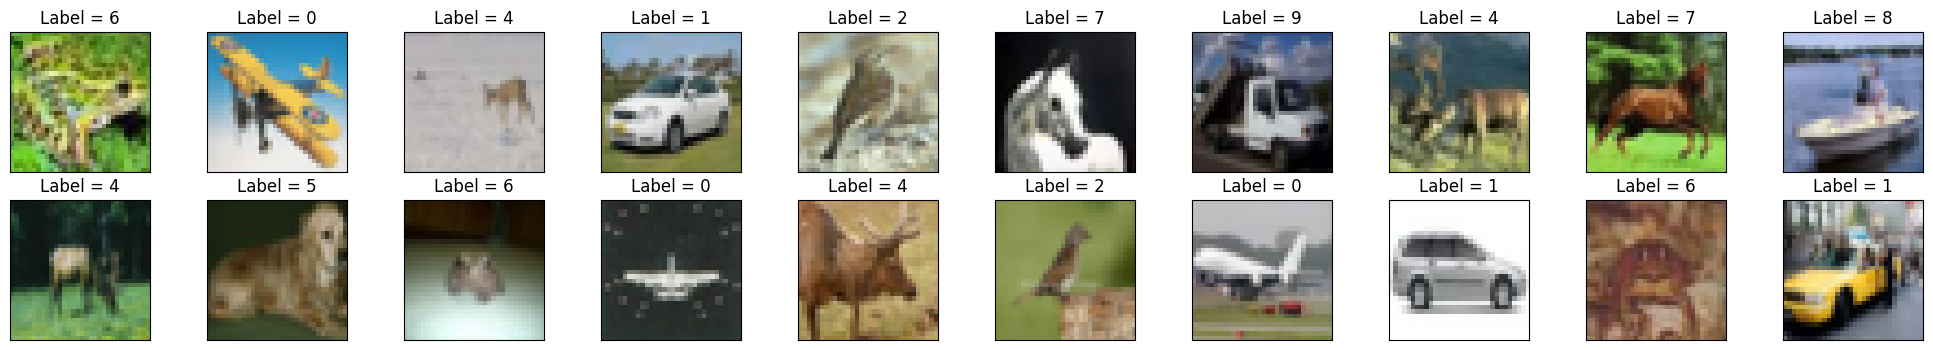

In [7]:
# Menampilkan data yang sudah dimuat mempertimbangkan iterator object
dataiter = iter(train_loader)
images, labels = next(dataiter)
fig = plt.figure(figsize=(25, 4))
for idx in range(20):
  ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
  plt.imshow(img_convert(images[idx]))
  ax.set_title("Label = " + str(labels[idx].item()))

In [8]:
# Pendefinisian fungsi untuk memperoleh ukuran dari quantized model
def get_file_size(file_path):
  return os.path.getsize(file_path)

In [9]:
# Tentukan folder penyimpanan log di Google Drive Anda
LOG_DIR = "/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs"
os.makedirs(LOG_DIR, exist_ok=True)

CSV_LOG_PATH = os.path.join(LOG_DIR, "cifar10_quantization_benchmark.csv")
JSON_LOG_PATH = os.path.join(LOG_DIR, "cifar10_quantization_benchmark.json")

FIGURE_DIR = os.path.join(LOG_DIR, "confusion_matrices")
os.makedirs(FIGURE_DIR, exist_ok=True)

QAT_PLOT_DIR = os.path.join(LOG_DIR, "qat_loss_curves")
os.makedirs(QAT_PLOT_DIR, exist_ok=True)

# Inisialisasi header file CSV jika belum dibuat
CSV_HEADERS = ["timestamp","seed","framework","method","runtime_backend","quant_scheme",
               "accuracy","macro_precision","macro_recall","macro_f1","model_size_mb",
               "size_reduction_pct","latency_mean_ms","latency_std_ms"]

if not os.path.exists(CSV_LOG_PATH):
  with open(CSV_LOG_PATH, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(CSV_HEADERS)
  print(f"---> File log CSV berhasil diinisialisasi: {CSV_LOG_PATH}")

## **2. Pendefinisian Model**

In [10]:
# Pembuatan model untuk CNN yang merujuk pada VGG-16Layer
# - in_channels (int) - Jumlah dari channels dalam data citra masukkan.
# - num_classes (int) - Jumlah class target yang akan digunakan sebagai neuron output pada FC akhir.
class VGG16(nn.Module):
  def __init__(self, in_channels=3, num_classes=10):
    super(VGG16, self).__init__()
    self.layer1 = nn.Sequential(
        nn.Conv2d(in_channels, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU())
    self.layer2 = nn.Sequential(
        nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer3 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU())
    self.layer4 = nn.Sequential(
        nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer5 = nn.Sequential(
        nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU())
    self.layer6 = nn.Sequential(
        nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU())
    self.layer7 = nn.Sequential(
        nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer8 = nn.Sequential(
        nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer9 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer10 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer11 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer12 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer13 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(1*1*512, 4096),
        nn.ReLU())
    self.fc1 = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(4096, 4096),
        nn.ReLU())
    self.fc2= nn.Sequential(
        nn.Linear(4096, num_classes))

  def forward(self, x):
    out = self.layer1(x)
    out = self.layer2(out)
    out = self.layer3(out)
    out = self.layer4(out)
    out = self.layer5(out)
    out = self.layer6(out)
    out = self.layer7(out)
    out = self.layer8(out)
    out = self.layer9(out)
    out = self.layer10(out)
    out = self.layer11(out)
    out = self.layer12(out)
    out = self.layer13(out)
    out = out.reshape(out.size(0), -1) #Flatten
    out = self.fc(out)
    out = self.fc1(out)
    out = self.fc2(out)
    return out

In [11]:
# Percobaan untuk melakukan setting arsitektur VGG pada suatu variabel
model = VGG16(input_channel,num_classes).to(device)

# Menampilkan summary proses pada setiap block
summary(model, input_size=(batch_size, 3, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
VGG16                                    [128, 10]                 --
├─Sequential: 1-1                        [128, 64, 32, 32]         --
│    └─Conv2d: 2-1                       [128, 64, 32, 32]         1,792
│    └─BatchNorm2d: 2-2                  [128, 64, 32, 32]         128
│    └─ReLU: 2-3                         [128, 64, 32, 32]         --
├─Sequential: 1-2                        [128, 64, 16, 16]         --
│    └─Conv2d: 2-4                       [128, 64, 32, 32]         36,928
│    └─BatchNorm2d: 2-5                  [128, 64, 32, 32]         128
│    └─ReLU: 2-6                         [128, 64, 32, 32]         --
│    └─MaxPool2d: 2-7                    [128, 64, 16, 16]         --
├─Sequential: 1-3                        [128, 128, 16, 16]        --
│    └─Conv2d: 2-8                       [128, 128, 16, 16]        73,856
│    └─BatchNorm2d: 2-9                  [128, 128, 16, 16]        256
│

In [12]:
# Pendefinisian fungsi untuk mengunci seluruh random generator untuk memastikan reproduktibilitas
# penuh pada inisialisasi bobot, data loader shuffle, dan perhitungan CUDA.
def set_deterministic_seed(seed: int):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
  print(f"\n---> [SYSTEM] Deterministic Random Seed berhasil diset ke: {seed}")

In [13]:
# Mendefiniskan function untuk menghitung acc, macro precision, dan macro recall untuk multiclass dari hasil prediksi CIFAR-10
def calculate_macro_metrics(outputs, labels, num_classes):
  value, labels_pred = torch.max(outputs, dim=1)
  if labels.dim() > 1:
    value, labels_actual = torch.max(labels, dim=1)
  else:
    labels_actual = labels

  acc = (labels_pred == labels_actual).float().mean()

  # Ekstraksi ke CPU numpy array untuk penghitungan metrik sklearn yang stabil
  y_pred_np = labels_pred.detach().cpu().numpy()
  y_true_np = labels_actual.detach().cpu().numpy()

  # Menghitung Macro F1, Precision, dan Recall (Zero division ditangani aman)
  macro_f1 = f1_score(y_true_np, y_pred_np, average='macro', zero_division=0)

  tp = torch.zeros(num_classes)
  fp = torch.zeros(num_classes)
  fn = torch.zeros(num_classes)

  for i in range(num_classes):
    tp[i] = ((labels_pred == i) & (labels_actual == i)).sum().item()
    fp[i] = ((labels_pred == i) & (labels_actual != i)).sum().item()
    fn[i] = ((labels_pred != i) & (labels_actual == i)).sum().item()

  epsilon = 1e-8
  class_precisions = tp / (tp + fp + epsilon)
  class_recalls = tp / (tp + fn + epsilon)

  macro_precision = class_precisions.mean()
  macro_recall = class_recalls.mean()

  return acc, macro_precision, macro_recall, macro_f1, y_true_np, y_pred_np

In [14]:
# Standarisasi Benchmarking Latensi CPU
# Menghitung mean dan standard deviation dari inference latency secara ketat
# pada CPU (menjawab Poin 2 & Poin 3 reviewer).
def benchmark_latency_cpu(model, sample_input, num_warmup=20, num_runs=100):
  model.eval()
  sample_input = sample_input.to("cpu")

  # Warm-up phase untuk stabilisasi CPU cache & thread dispatch
  with torch.inference_mode():
    for _ in range(num_warmup):
      _ = model(sample_input)

  latencies = []
  with torch.inference_mode():
    for _ in range(num_runs):
      start = time.perf_counter()
      _ = model(sample_input)
      end = time.perf_counter()
      latencies.append((end - start) * 1000.0) # ms

  latencies = np.array(latencies)
  return latencies.mean(), latencies.std()

In [15]:
# Menampilkan dan menyimpan Confusion Matrix (default: dinormalisasi per-kelas 0.0 - 1.0)
def plot_and_save_confusion_matrix(y_true, y_pred, title, save_path=None, normalize=True):
  CIFAR10_CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

  cm = confusion_matrix(y_true, y_pred)
  fmt = 'd'
  if normalize:
    cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    fmt = '.2f'

  plt.figure(figsize=(9, 7))
  sns.heatmap(
      cm,
      annot=True,
      fmt=fmt,
      cmap='Blues',
      xticklabels=CIFAR10_CLASSES,
      yticklabels=CIFAR10_CLASSES,
      cbar=True
  )
  plt.title(title, fontsize=14, pad=12)
  plt.xlabel('Predicted Label', fontsize=12)
  plt.ylabel('True Ground Truth Label', fontsize=12)
  plt.tight_layout()

  if save_path:
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"[CM SAVED] Confusion matrix tersimpan di: {save_path}")
  plt.show()

In [16]:
# Menganalisis dan mencetak kelas CIFAR-10 yang paling terdampak (mengalami penurunan
# akurasi terbesar) akibat proses kuantisasi dibandingkan baseline FP32.
def analyze_most_degraded_classes(y_true, y_pred_fp32, y_pred_quant, method_name="Quantized Model"):
  CIFAR10_CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

  cm_fp32 = confusion_matrix(y_true, y_pred_fp32, normalize='true')
  cm_quant = confusion_matrix(y_true, y_pred_quant, normalize='true')

  acc_per_class_fp32 = cm_fp32.diagonal() * 100.0
  acc_per_class_quant = cm_quant.diagonal() * 100.0
  diff = acc_per_class_quant - acc_per_class_fp32 # Nilai negatif mengindikasikan penurunan

  print(f"\n{'='*70}")
  print(f" ANALISIS DEGRADASI AKURASI PER-KELAS: {method_name} vs Baseline FP32")
  print(f"{'='*70}")
  print(f"{'Class':<12} | {'FP32 Acc (%)':<14} | {'Quant Acc (%)':<14} | {'Degradasi / Delta (%)':<18}")
  print(f"{'-'*70}")

  sorted_indices = np.argsort(diff) # Urutkan dari yang paling turun
  for idx in sorted_indices:
    cls_name = CIFAR10_CLASSES[idx]
    delta_str = f"{diff[idx]:+.2f}%"
    print(f"{cls_name:<12} | {acc_per_class_fp32[idx]:<14.2f} | {acc_per_class_quant[idx]:<14.2f} | {delta_str:<18}")

  most_affected_idx = sorted_indices[0]
  print(f"{'-'*70}")
  print(f"---> KELAS PALING TERDAMPAK: '{CIFAR10_CLASSES[most_affected_idx]}' dengan delta {diff[most_affected_idx]:.2f}%\n")

In [17]:
# Mengekstrak seluruh prediksi dan label asli pada seluruh dataset test.
def get_all_predictions_torch(model, data_loader, eval_device="cpu"):
  model.eval()
  all_preds = []
  all_targets = []

  with torch.inference_mode():
    for images, labels in data_loader:
      images = images.to(eval_device)
      outputs = model(images)
      preds = torch.argmax(outputs, dim=1).cpu().numpy()

      all_preds.extend(preds)
      all_targets.extend(labels.numpy())

  return np.array(all_targets), np.array(all_preds)

In [18]:
# Pendefinisian fungsi untuk menyimpan satu baris data eksperimen ke CSV dan memperbarui riwayat di JSON.
def log_experiment_result(seed: int, framework: str, method: str, runtime_backend: str, quant_scheme: str,
                          accuracy: float, macro_precision: float, macro_recall: float, macro_f1: float,
                          model_size_mb: float, baseline_size_mb: float, latency_mean_ms: float,
                          latency_std_ms: float):

  # Hitung persentase kompresi ukuran model terhadap baseline
  size_reduction = (1.0 - (model_size_mb / baseline_size_mb)) * 100.0 if baseline_size_mb > 0 else 0.0
  now_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

  # Siapkan payload baris data
  row_dict = {
      "timestamp": now_str,
      "seed": seed,
      "framework": framework,
      "method": method,
      "runtime_backend": runtime_backend,
      "quant_scheme": quant_scheme,
      "accuracy": round(float(accuracy), 4),
      "macro_precision": round(float(macro_precision), 4),
      "macro_recall": round(float(macro_recall), 4),
      "macro_f1": round(float(macro_f1), 4),
      "model_size_mb": round(float(model_size_mb), 2),
      "size_reduction_pct": round(float(size_reduction), 2),
      "latency_mean_ms": round(float(latency_mean_ms), 2),
      "latency_std_ms": round(float(latency_std_ms), 2)
  }

  # 1. Append ke File CSV
  with open(CSV_LOG_PATH, mode="a", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=CSV_HEADERS)
    writer.writerow(row_dict)

  # 2. Append ke File JSON
  all_logs = []
  if os.path.exists(JSON_LOG_PATH):
    try:
      with open(JSON_LOG_PATH, mode="r", encoding="utf-8") as jf:
        all_logs = json.load(jf)
    except json.JSONDecodeError:
      all_logs = []

  all_logs.append(row_dict)
  with open(JSON_LOG_PATH, mode="w", encoding="utf-8") as jf:
    json.dump(all_logs, jf, indent=4)

  print(f"[LOG SUCCESS] {framework} - {method} (Seed: {seed}) tercatat di file eksternal.")

In [19]:
# Pembuatan model berbasis VGG-16Layer dengan Quantization
class VGG16_Quantization(nn.Module):
  def __init__(self, in_channels=3, num_classes=10):
    super(VGG16_Quantization, self).__init__()

    # QuantStub digunakan untuk mengubah tensors dari floating point ke quantized
    self.quant = torch.ao.quantization.QuantStub()

    self.layer1 = nn.Sequential(
        nn.Conv2d(in_channels, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU())
    self.layer2 = nn.Sequential(
        nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer3 = nn.Sequential(
        nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU())
    self.layer4 = nn.Sequential(
        nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer5 = nn.Sequential(
        nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU())
    self.layer6 = nn.Sequential(
        nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU())
    self.layer7 = nn.Sequential(
        nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer8 = nn.Sequential(
        nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer9 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer10 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.layer11 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer12 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU())
    self.layer13 = nn.Sequential(
        nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2, stride = 2))
    self.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(1*1*512, 4096),
        nn.ReLU())
    self.fc1 = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(4096, 4096),
        nn.ReLU())
    self.fc2= nn.Sequential(
        nn.Linear(4096, num_classes))

    # DeQuantStub mengubah tensors dari quantized ke floating point
    self.dequant = torch.ao.quantization.DeQuantStub()

  def forward(self, x):
    out = self.quant(x)
    out = self.layer1(out)
    # print(out.dtype)
    out = self.layer2(out)
    out = self.layer3(out)
    out = self.layer4(out)
    out = self.layer5(out)
    out = self.layer6(out)
    out = self.layer7(out)
    out = self.layer8(out)
    out = self.layer9(out)
    out = self.layer10(out)
    out = self.layer11(out)
    out = self.layer12(out)
    out = self.layer13(out)
    out = out.reshape(out.size(0), -1) #Flatten
    out = self.fc(out)
    out = self.fc1(out)
    out = self.fc2(out)
    out = self.dequant(out)
    return out

In [20]:
class VGG16_Quantization2(nn.Module):
  def __init__(self, fp32_model):
    super(VGG16_Quantization2, self).__init__()
    self.fp32_model = fp32_model
    self.quant = torch.ao.quantization.QuantStub()
    self.dequant = torch.ao.quantization.DeQuantStub()

  def forward(self, x):
    out = self.quant(x)
    out = self.fp32_model(out)
    out = self.dequant(out)
    return out

## **3. Eksekusi Eksperimen Multi-Seed Berulang**

In [25]:
# Tentukan daftar seed (3 perulangan independen)
MODEL_CHECKPOINT_DIR = "/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/model saved (revisi)"
SEEDS = [42, 123, 456, 1337, 2024]
num_epochs_baseline = 20
num_epochs_qat = 10
all_qat_train_losses = []
all_qat_test_losses = []


============================== MEMULAI RUN KE-1 (SEED 42) ==============================

---> [SYSTEM] Deterministic Random Seed berhasil diset ke: 42
Checkpoint /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/model saved (revisi)/model_vgg16_fp32_baseline_seed42.pth berhasil dimuat.
[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_fp32_baseline_seed42.png


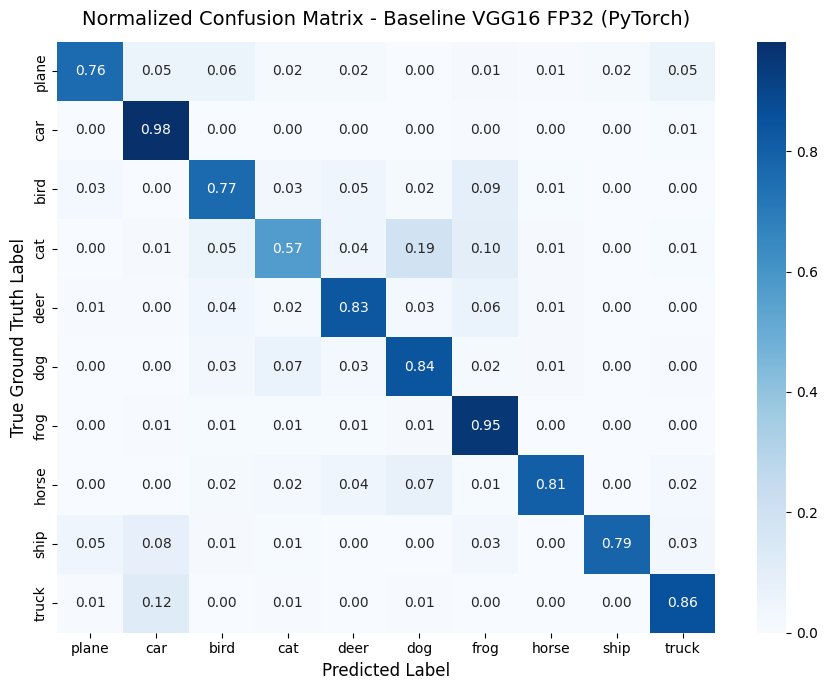

/tmp/ipykernel_625/743847843.py:50: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_ptsq_prepared = torch.ao.quantization.prepare(model_ptsq_fused)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a 

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptsq_torch_ao_seed42.png


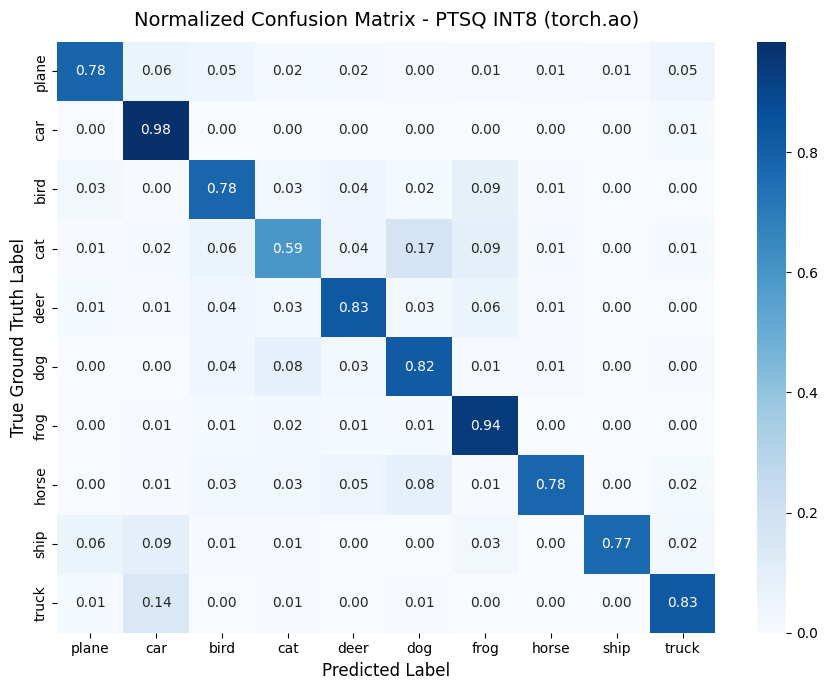


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
truck        | 85.60          | 82.80          | -2.80%            
horse        | 80.50          | 78.00          | -2.50%            
dog          | 84.10          | 82.20          | -1.90%            
ship         | 78.50          | 76.90          | -1.60%            
frog         | 95.20          | 94.00          | -1.20%            
deer         | 83.30          | 83.00          | -0.30%            
car          | 98.20          | 98.40          | +0.20%            
bird         | 76.50          | 77.80          | +1.30%            
plane        | 76.30          | 78.10          | +1.80%            
cat          | 56.80          | 59.40          | +2.60%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'truc

/tmp/ipykernel_625/743847843.py:72: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_ptdq = torch.ao.quantization.quantize_dynamic(


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_torch_ao_seed42.png


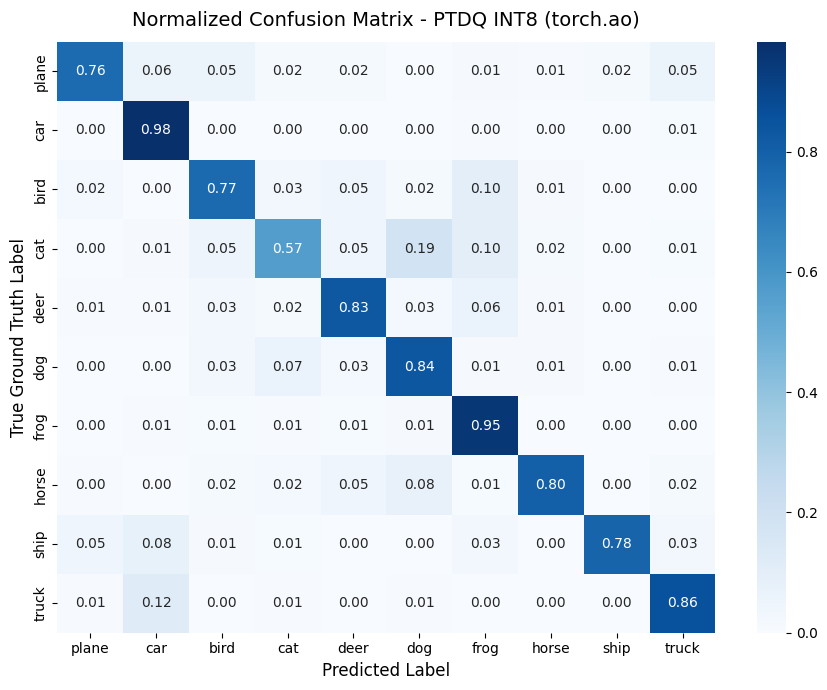


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
horse        | 80.50          | 80.00          | -0.50%            
dog          | 84.10          | 83.70          | -0.40%            
cat          | 56.80          | 56.70          | -0.10%            
ship         | 78.50          | 78.40          | -0.10%            
deer         | 83.30          | 83.30          | +0.00%            
bird         | 76.50          | 76.50          | +0.00%            
car          | 98.20          | 98.30          | +0.10%            
plane        | 76.30          | 76.40          | +0.10%            
frog         | 95.20          | 95.30          | +0.10%            
truck        | 85.60          | 85.70          | +0.10%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'hors

/tmp/ipykernel_625/743847843.py:105: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.quantization.prepare_qat(quantized_qat, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future re


--- Memulai Fine-Tuning QAT (Seed: 42) ---
Epoch [1/10] -> QAT Train Loss: 0.0971 | QAT Test Loss: 0.7537
Epoch [2/10] -> QAT Train Loss: 0.0960 | QAT Test Loss: 0.6660
Epoch [3/10] -> QAT Train Loss: 0.0508 | QAT Test Loss: 0.7284
Epoch [4/10] -> QAT Train Loss: 0.0456 | QAT Test Loss: 0.7457
Epoch [5/10] -> QAT Train Loss: 0.0482 | QAT Test Loss: 0.7284
Epoch [6/10] -> QAT Train Loss: 0.0457 | QAT Test Loss: 0.7436
Epoch [7/10] -> QAT Train Loss: 0.0386 | QAT Test Loss: 0.7170
Epoch [8/10] -> QAT Train Loss: 0.0433 | QAT Test Loss: 0.7280
Epoch [9/10] -> QAT Train Loss: 0.0373 | QAT Test Loss: 0.7805
Epoch [10/10] -> QAT Train Loss: 0.0352 | QAT Test Loss: 0.7540


/tmp/ipykernel_625/743847843.py:164: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_qat = torch.quantization.convert(quantized_qat, inplace=False)


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_qat_torch_ao_seed42.png


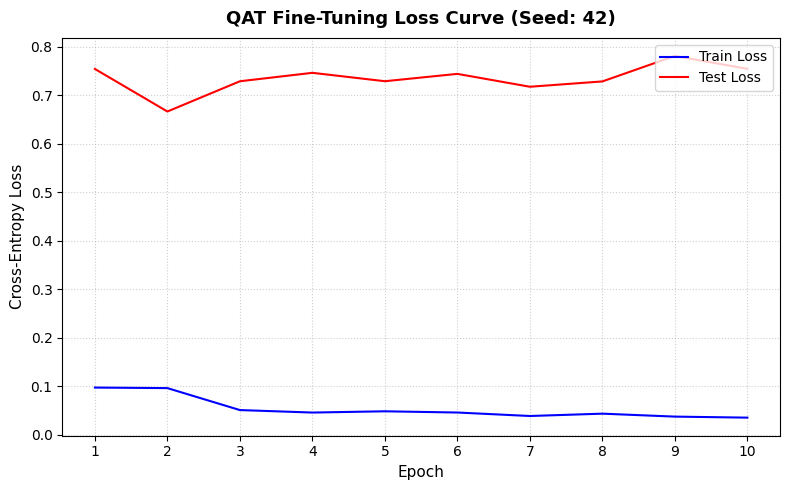

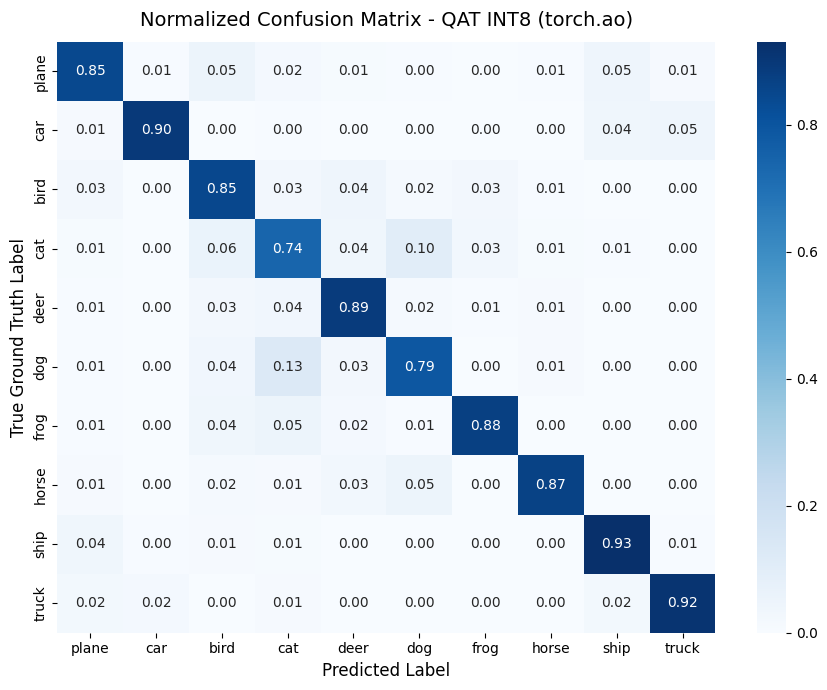


 ANALISIS DEGRADASI AKURASI PER-KELAS: QAT (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
car          | 98.20          | 89.50          | -8.70%            
frog         | 95.20          | 87.60          | -7.60%            
dog          | 84.10          | 79.00          | -5.10%            
deer         | 83.30          | 88.90          | +5.60%            
truck        | 85.60          | 91.50          | +5.90%            
horse        | 80.50          | 86.70          | +6.20%            
plane        | 76.30          | 84.60          | +8.30%            
bird         | 76.50          | 85.00          | +8.50%            
ship         | 78.50          | 93.10          | +14.60%           
cat          | 56.80          | 74.00          | +17.20%           
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'car' 

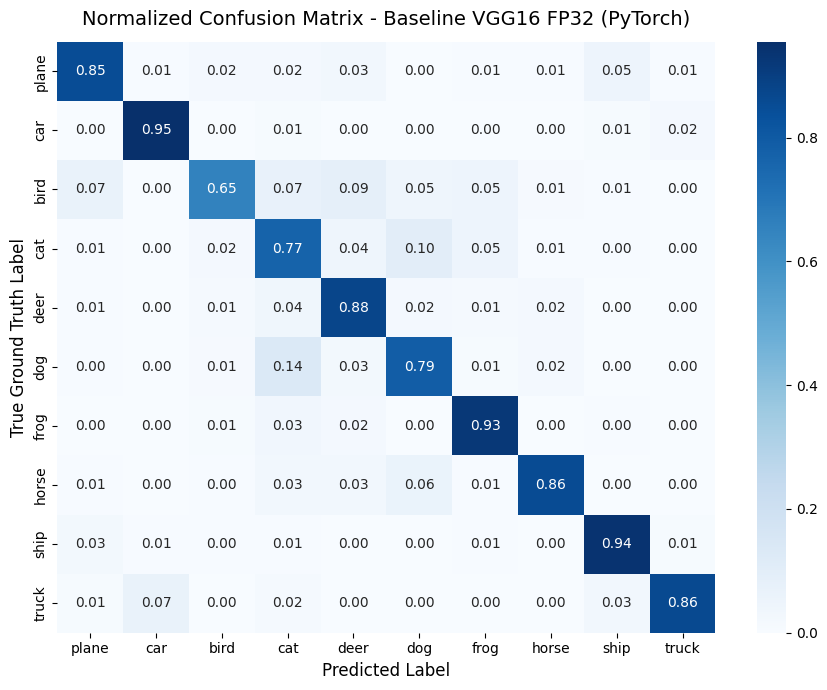

/tmp/ipykernel_625/743847843.py:50: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_ptsq_prepared = torch.ao.quantization.prepare(model_ptsq_fused)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a 

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptsq_torch_ao_seed123.png


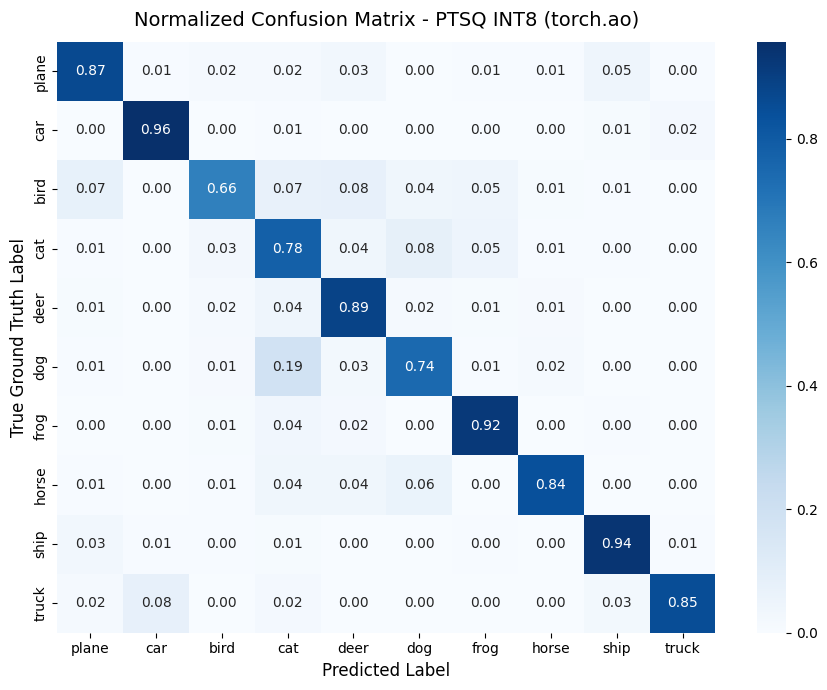


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
dog          | 79.00          | 74.40          | -4.60%            
horse        | 85.80          | 83.80          | -2.00%            
truck        | 86.50          | 85.00          | -1.50%            
ship         | 94.10          | 93.60          | -0.50%            
frog         | 92.50          | 92.20          | -0.30%            
car          | 95.50          | 95.70          | +0.20%            
deer         | 88.00          | 88.70          | +0.70%            
bird         | 65.40          | 66.40          | +1.00%            
plane        | 85.40          | 86.70          | +1.30%            
cat          | 76.50          | 77.90          | +1.40%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'dog'

/tmp/ipykernel_625/743847843.py:72: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_ptdq = torch.ao.quantization.quantize_dynamic(


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_torch_ao_seed123.png


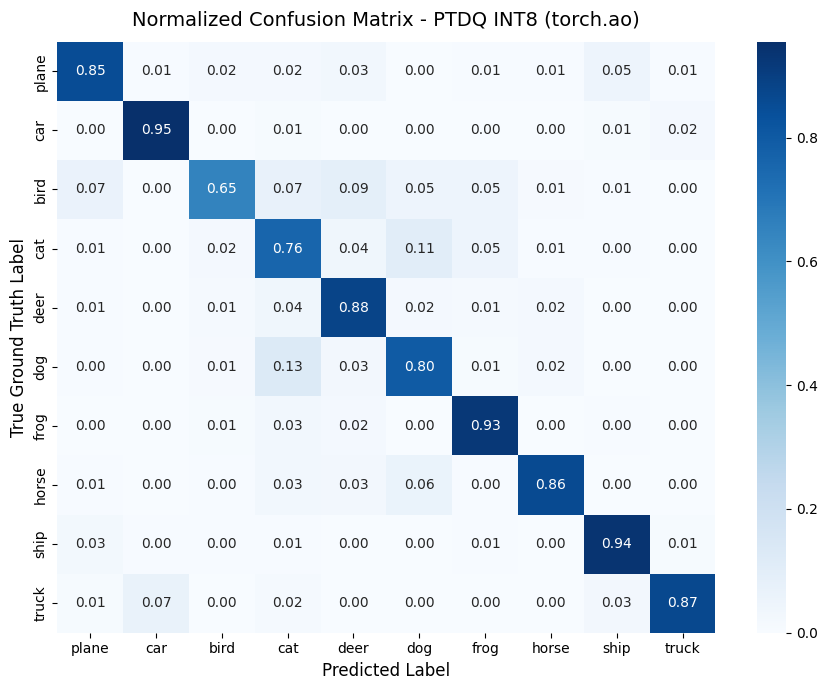


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
cat          | 76.50          | 76.10          | -0.40%            
plane        | 85.40          | 85.10          | -0.30%            
bird         | 65.40          | 65.20          | -0.20%            
ship         | 94.10          | 94.00          | -0.10%            
frog         | 92.50          | 92.50          | +0.00%            
car          | 95.50          | 95.50          | +0.00%            
deer         | 88.00          | 88.10          | +0.10%            
horse        | 85.80          | 86.00          | +0.20%            
truck        | 86.50          | 86.70          | +0.20%            
dog          | 79.00          | 79.50          | +0.50%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'cat'

/tmp/ipykernel_625/743847843.py:105: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.quantization.prepare_qat(quantized_qat, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future re


--- Memulai Fine-Tuning QAT (Seed: 123) ---
Epoch [1/10] -> QAT Train Loss: 0.0919 | QAT Test Loss: 0.7269
Epoch [2/10] -> QAT Train Loss: 0.0695 | QAT Test Loss: 0.6764
Epoch [3/10] -> QAT Train Loss: 0.0629 | QAT Test Loss: 0.6630
Epoch [4/10] -> QAT Train Loss: 0.0474 | QAT Test Loss: 0.7370
Epoch [5/10] -> QAT Train Loss: 0.0525 | QAT Test Loss: 0.7499
Epoch [6/10] -> QAT Train Loss: 0.0474 | QAT Test Loss: 0.7610
Epoch [7/10] -> QAT Train Loss: 0.0389 | QAT Test Loss: 0.6969
Epoch [8/10] -> QAT Train Loss: 0.0344 | QAT Test Loss: 0.8687
Epoch [9/10] -> QAT Train Loss: 0.0402 | QAT Test Loss: 1.0275
Epoch [10/10] -> QAT Train Loss: 0.0373 | QAT Test Loss: 0.7681


/tmp/ipykernel_625/743847843.py:164: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_qat = torch.quantization.convert(quantized_qat, inplace=False)


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_qat_torch_ao_seed123.png


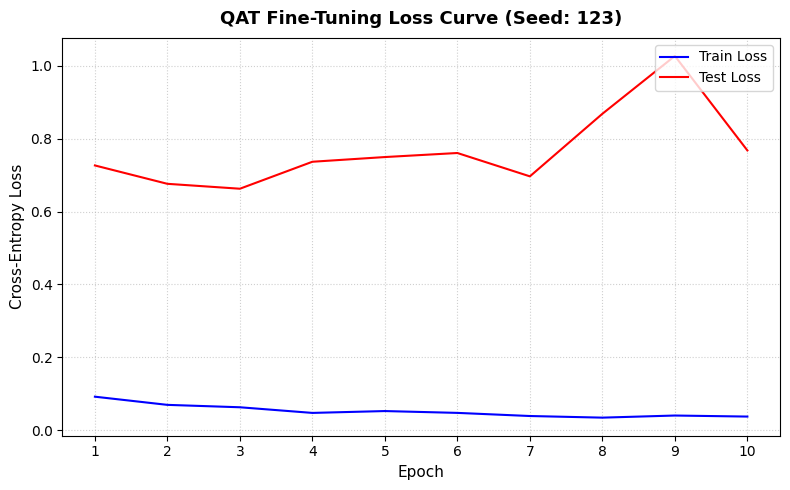

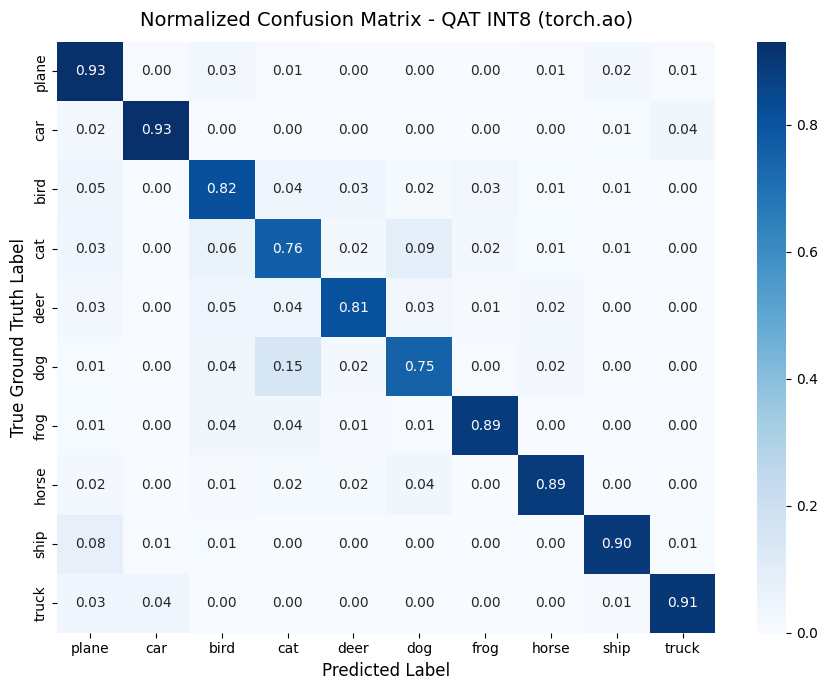


 ANALISIS DEGRADASI AKURASI PER-KELAS: QAT (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
deer         | 88.00          | 81.30          | -6.70%            
ship         | 94.10          | 89.60          | -4.50%            
dog          | 79.00          | 75.20          | -3.80%            
frog         | 92.50          | 89.00          | -3.50%            
car          | 95.50          | 93.10          | -2.40%            
cat          | 76.50          | 76.20          | -0.30%            
horse        | 85.80          | 89.00          | +3.20%            
truck        | 86.50          | 90.50          | +4.00%            
plane        | 85.40          | 92.80          | +7.40%            
bird         | 65.40          | 81.80          | +16.40%           
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'deer'

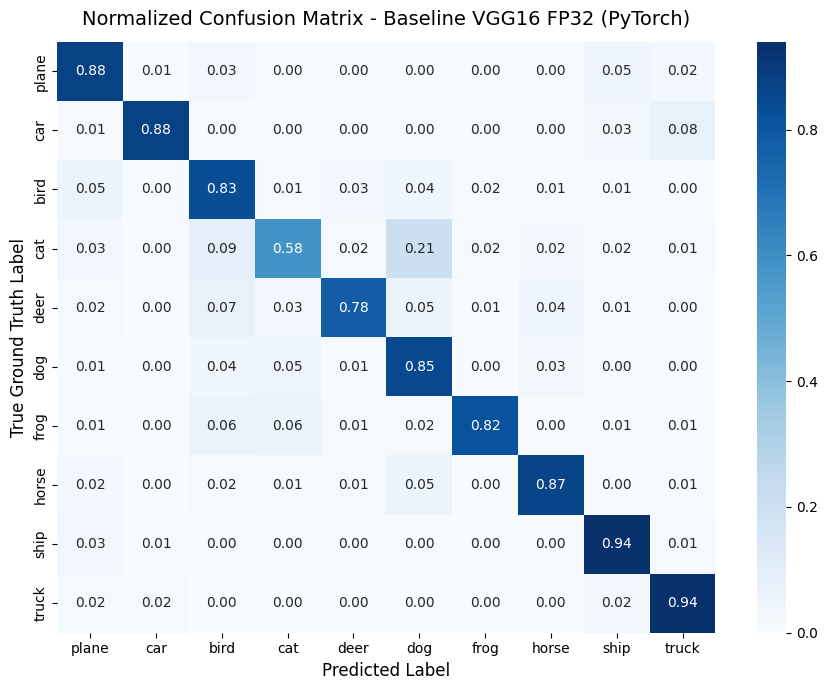

/tmp/ipykernel_625/743847843.py:50: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_ptsq_prepared = torch.ao.quantization.prepare(model_ptsq_fused)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a 

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptsq_torch_ao_seed456.png


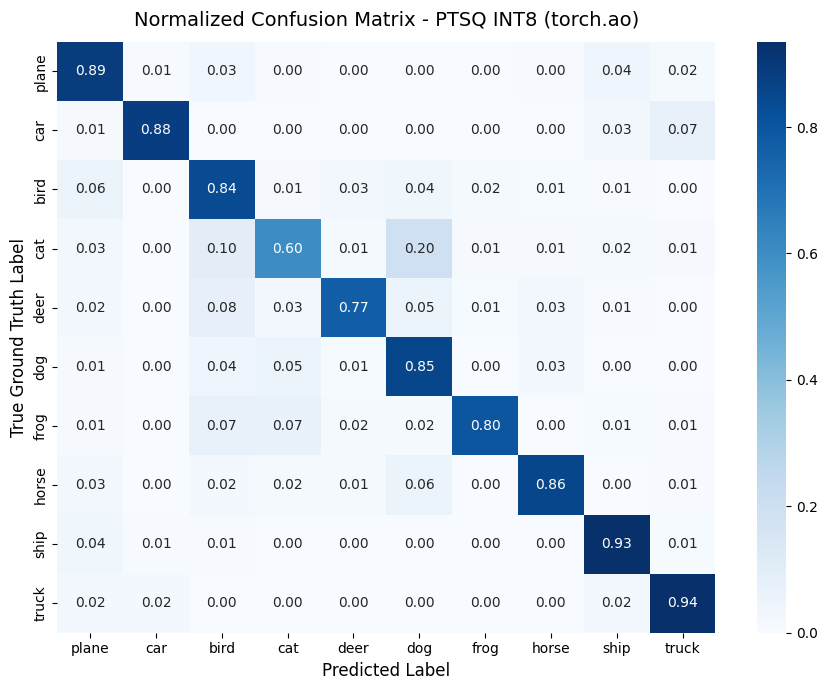


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
frog         | 81.80          | 79.90          | -1.90%            
horse        | 86.70          | 85.80          | -0.90%            
deer         | 77.60          | 76.90          | -0.70%            
truck        | 94.00          | 93.50          | -0.50%            
ship         | 93.80          | 93.40          | -0.40%            
dog          | 85.20          | 85.50          | +0.30%            
bird         | 83.40          | 83.70          | +0.30%            
car          | 87.60          | 88.30          | +0.70%            
plane        | 88.00          | 88.80          | +0.80%            
cat          | 58.30          | 59.90          | +1.60%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'frog

/tmp/ipykernel_625/743847843.py:72: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_ptdq = torch.ao.quantization.quantize_dynamic(


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_torch_ao_seed456.png


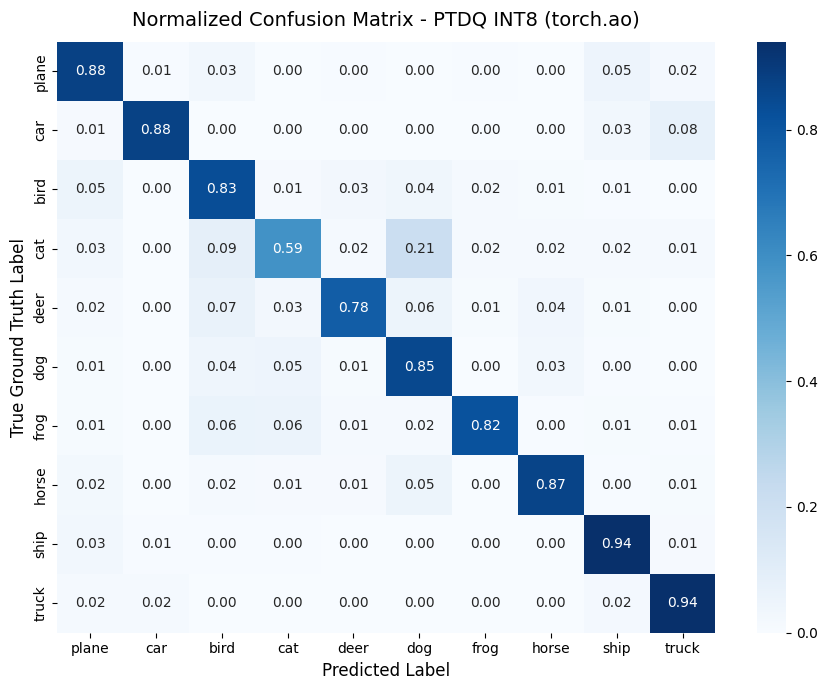


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
frog         | 81.80          | 81.70          | -0.10%            
ship         | 93.80          | 93.70          | -0.10%            
deer         | 77.60          | 77.60          | +0.00%            
plane        | 88.00          | 88.00          | +0.00%            
dog          | 85.20          | 85.20          | +0.00%            
horse        | 86.70          | 86.70          | +0.00%            
truck        | 94.00          | 94.00          | +0.00%            
car          | 87.60          | 87.60          | +0.00%            
bird         | 83.40          | 83.50          | +0.10%            
cat          | 58.30          | 58.60          | +0.30%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'frog

/tmp/ipykernel_625/743847843.py:105: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.quantization.prepare_qat(quantized_qat, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future re


--- Memulai Fine-Tuning QAT (Seed: 456) ---
Epoch [1/10] -> QAT Train Loss: 0.0906 | QAT Test Loss: 0.6287
Epoch [2/10] -> QAT Train Loss: 0.0596 | QAT Test Loss: 0.7245
Epoch [3/10] -> QAT Train Loss: 0.0619 | QAT Test Loss: 0.7534
Epoch [4/10] -> QAT Train Loss: 0.0489 | QAT Test Loss: 0.7100
Epoch [5/10] -> QAT Train Loss: 0.0448 | QAT Test Loss: 0.8226
Epoch [6/10] -> QAT Train Loss: 0.0468 | QAT Test Loss: 0.5890
Epoch [7/10] -> QAT Train Loss: 0.0403 | QAT Test Loss: 0.7175
Epoch [8/10] -> QAT Train Loss: 0.0364 | QAT Test Loss: 0.7185
Epoch [9/10] -> QAT Train Loss: 0.0241 | QAT Test Loss: 0.8757
Epoch [10/10] -> QAT Train Loss: 0.0351 | QAT Test Loss: 0.7745


/tmp/ipykernel_625/743847843.py:164: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_qat = torch.quantization.convert(quantized_qat, inplace=False)


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_qat_torch_ao_seed456.png


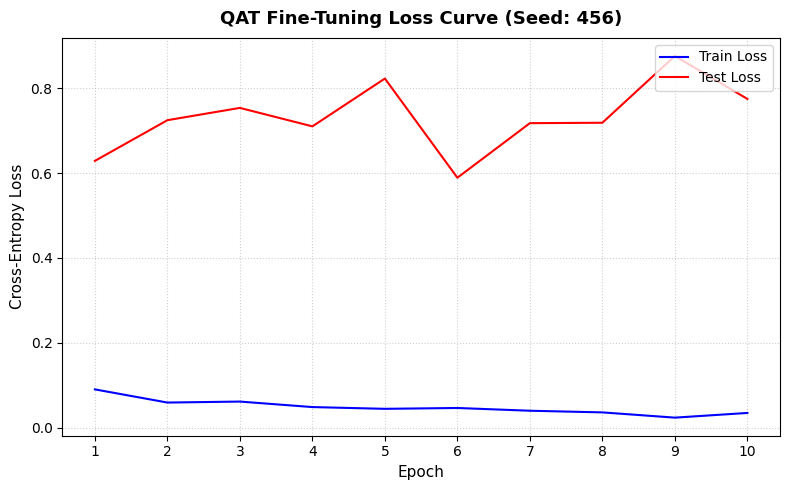

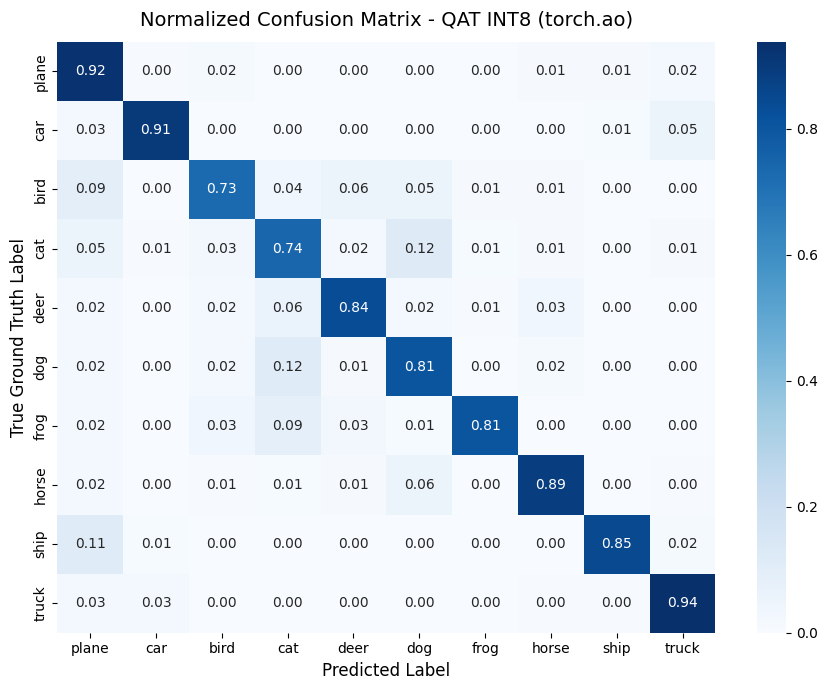


 ANALISIS DEGRADASI AKURASI PER-KELAS: QAT (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
bird         | 83.40          | 73.10          | -10.30%           
ship         | 93.80          | 84.80          | -9.00%            
dog          | 85.20          | 80.60          | -4.60%            
frog         | 81.80          | 80.60          | -1.20%            
truck        | 94.00          | 93.80          | -0.20%            
horse        | 86.70          | 88.90          | +2.20%            
car          | 87.60          | 90.50          | +2.90%            
plane        | 88.00          | 92.40          | +4.40%            
deer         | 77.60          | 83.60          | +6.00%            
cat          | 58.30          | 74.10          | +15.80%           
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'bird'

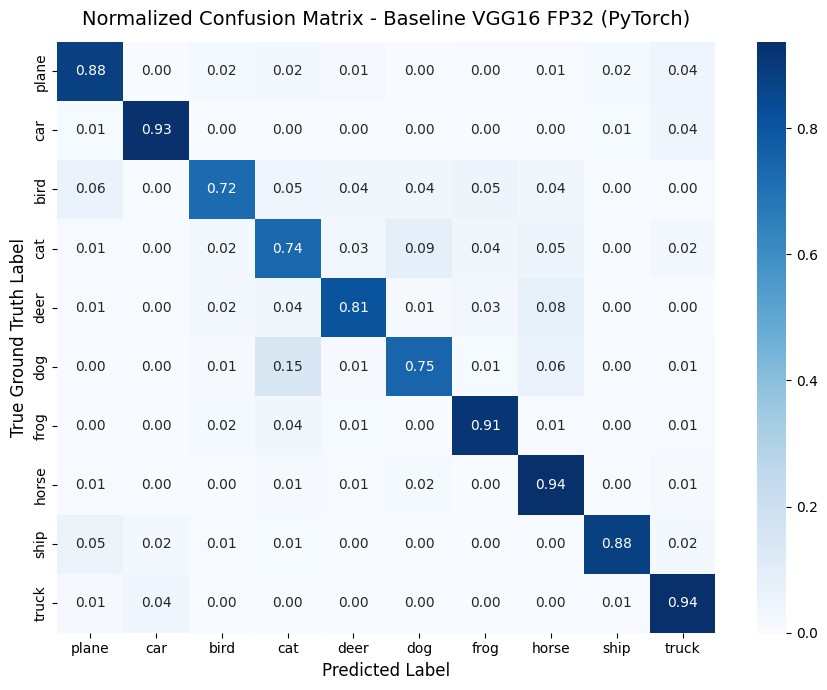

/tmp/ipykernel_625/743847843.py:50: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_ptsq_prepared = torch.ao.quantization.prepare(model_ptsq_fused)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a 

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptsq_torch_ao_seed1337.png


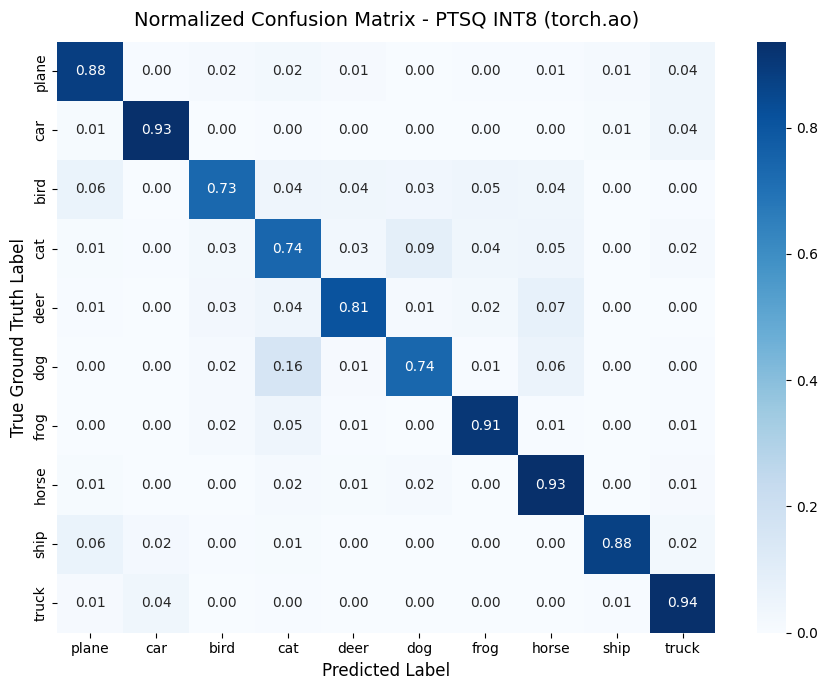


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
dog          | 74.60          | 73.70          | -0.90%            
ship         | 88.20          | 87.70          | -0.50%            
frog         | 91.40          | 91.00          | -0.40%            
horse        | 93.50          | 93.30          | -0.20%            
truck        | 93.70          | 93.60          | -0.10%            
car          | 93.10          | 93.30          | +0.20%            
deer         | 80.70          | 80.90          | +0.20%            
plane        | 88.00          | 88.30          | +0.30%            
cat          | 73.70          | 74.00          | +0.30%            
bird         | 72.50          | 73.30          | +0.80%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'dog'

/tmp/ipykernel_625/743847843.py:72: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_ptdq = torch.ao.quantization.quantize_dynamic(


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_torch_ao_seed1337.png


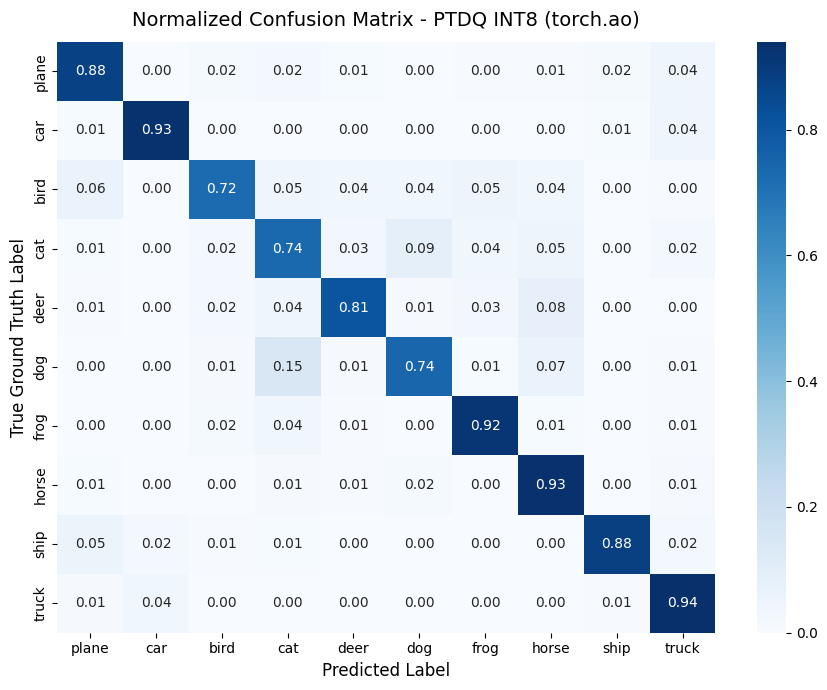


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
plane        | 88.00          | 87.80          | -0.20%            
dog          | 74.60          | 74.40          | -0.20%            
horse        | 93.50          | 93.40          | -0.10%            
car          | 93.10          | 93.10          | +0.00%            
cat          | 73.70          | 73.70          | +0.00%            
bird         | 72.50          | 72.50          | +0.00%            
deer         | 80.70          | 80.70          | +0.00%            
ship         | 88.20          | 88.20          | +0.00%            
frog         | 91.40          | 91.50          | +0.10%            
truck        | 93.70          | 94.00          | +0.30%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'plan

/tmp/ipykernel_625/743847843.py:105: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.quantization.prepare_qat(quantized_qat, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future re


--- Memulai Fine-Tuning QAT (Seed: 1337) ---
Epoch [1/10] -> QAT Train Loss: 0.0993 | QAT Test Loss: 0.6483
Epoch [2/10] -> QAT Train Loss: 0.0681 | QAT Test Loss: 0.8499
Epoch [3/10] -> QAT Train Loss: 0.0660 | QAT Test Loss: 0.7508
Epoch [4/10] -> QAT Train Loss: 0.0631 | QAT Test Loss: 0.5835
Epoch [5/10] -> QAT Train Loss: 0.0563 | QAT Test Loss: 0.7112
Epoch [6/10] -> QAT Train Loss: 0.0498 | QAT Test Loss: 0.6823
Epoch [7/10] -> QAT Train Loss: 0.0460 | QAT Test Loss: 0.7070
Epoch [8/10] -> QAT Train Loss: 0.0450 | QAT Test Loss: 0.7064
Epoch [9/10] -> QAT Train Loss: 0.0288 | QAT Test Loss: 0.8095
Epoch [10/10] -> QAT Train Loss: 0.0438 | QAT Test Loss: 0.8247


/tmp/ipykernel_625/743847843.py:164: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_qat = torch.quantization.convert(quantized_qat, inplace=False)


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_qat_torch_ao_seed1337.png


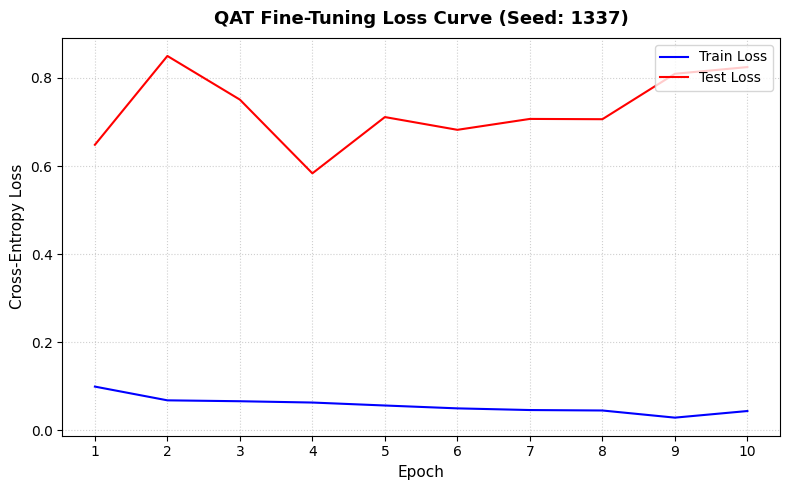

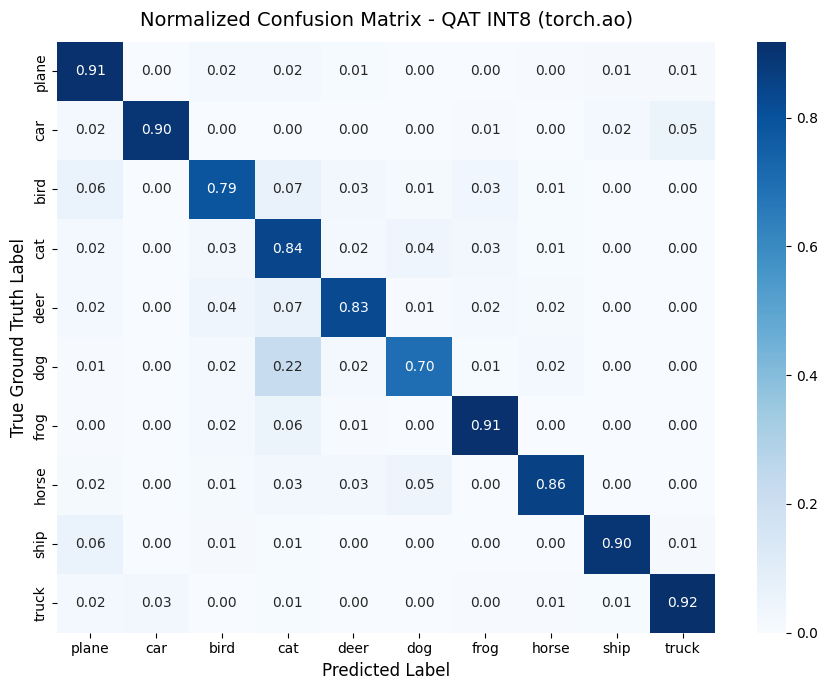


 ANALISIS DEGRADASI AKURASI PER-KELAS: QAT (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
horse        | 93.50          | 85.90          | -7.60%            
dog          | 74.60          | 69.70          | -4.90%            
car          | 93.10          | 89.80          | -3.30%            
truck        | 93.70          | 91.80          | -1.90%            
frog         | 91.40          | 91.20          | -0.20%            
ship         | 88.20          | 90.00          | +1.80%            
deer         | 80.70          | 83.00          | +2.30%            
plane        | 88.00          | 91.40          | +3.40%            
bird         | 72.50          | 78.70          | +6.20%            
cat          | 73.70          | 84.40          | +10.70%           
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'horse

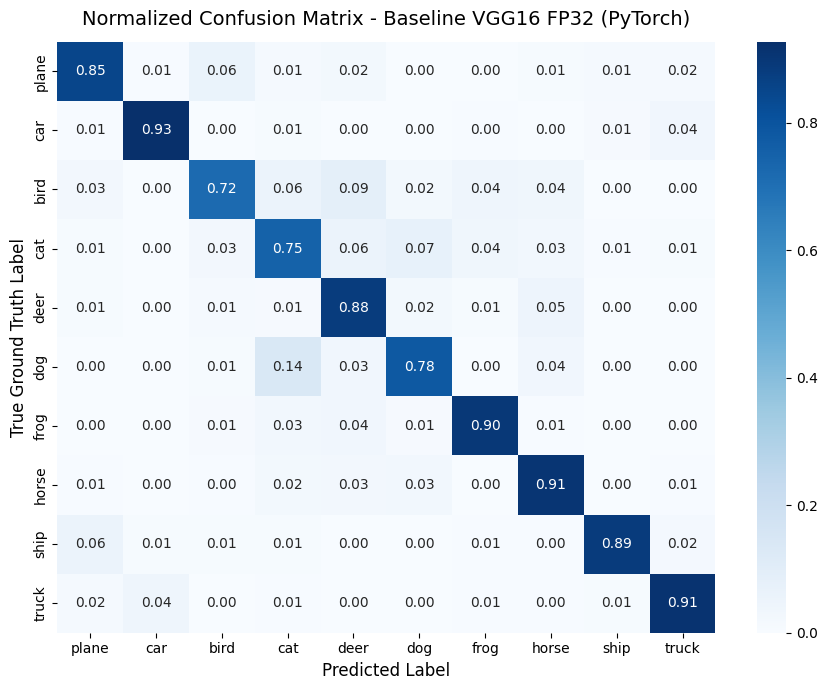

/tmp/ipykernel_625/743847843.py:50: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_ptsq_prepared = torch.ao.quantization.prepare(model_ptsq_fused)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a 

[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptsq_torch_ao_seed2024.png


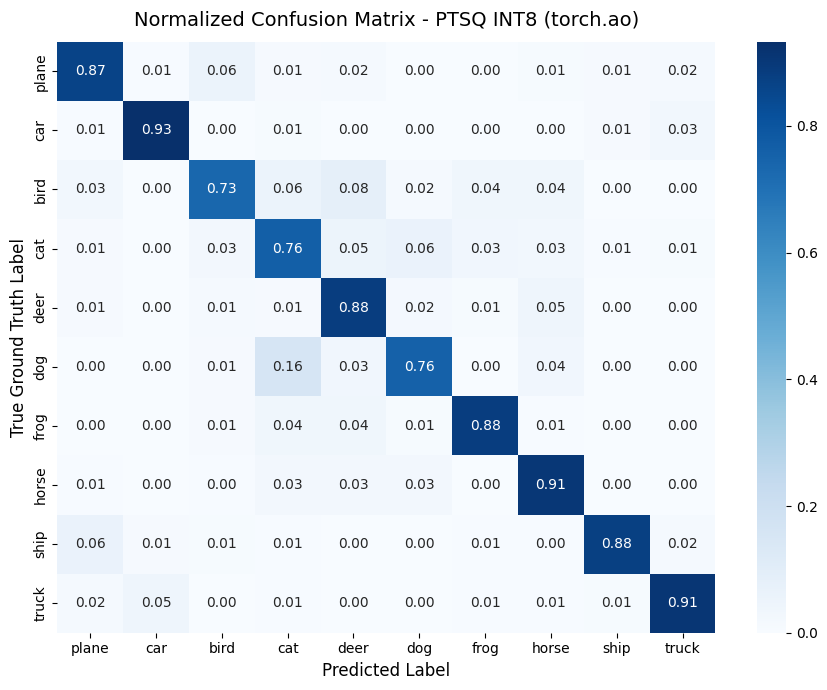


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTSQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
dog          | 77.90          | 75.70          | -2.20%            
frog         | 89.50          | 88.30          | -1.20%            
ship         | 88.60          | 87.80          | -0.80%            
truck        | 91.30          | 90.80          | -0.50%            
horse        | 90.60          | 90.60          | +0.00%            
deer         | 88.00          | 88.30          | +0.30%            
car          | 92.70          | 93.30          | +0.60%            
bird         | 72.00          | 73.30          | +1.30%            
plane        | 85.10          | 86.70          | +1.60%            
cat          | 74.70          | 76.40          | +1.70%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'dog'

/tmp/ipykernel_625/743847843.py:72: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_ptdq = torch.ao.quantization.quantize_dynamic(


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_ptdq_torch_ao_seed2024.png


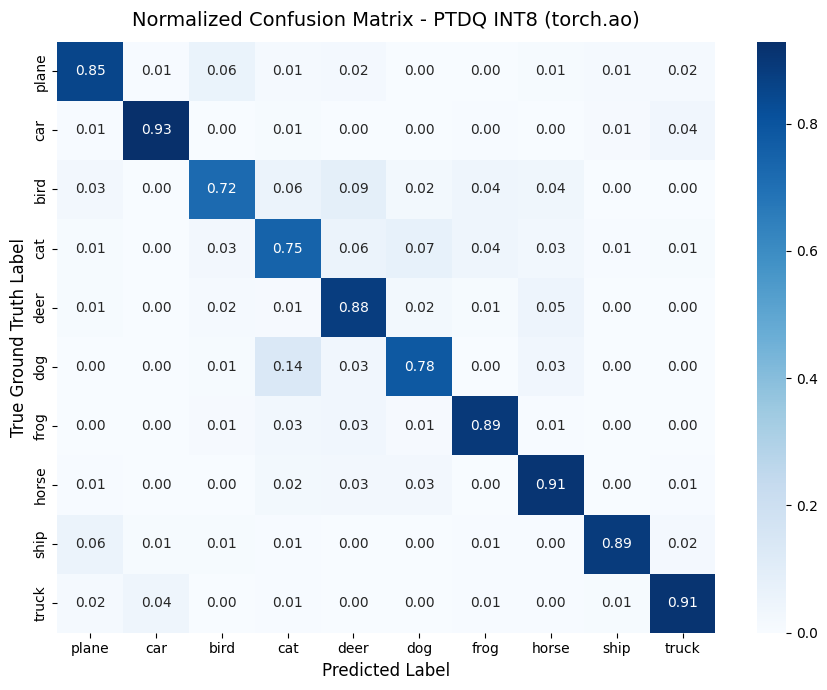


 ANALISIS DEGRADASI AKURASI PER-KELAS: PTDQ (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
frog         | 89.50          | 89.40          | -0.10%            
cat          | 74.70          | 74.70          | +0.00%            
deer         | 88.00          | 88.00          | +0.00%            
bird         | 72.00          | 72.00          | +0.00%            
truck        | 91.30          | 91.30          | +0.00%            
ship         | 88.60          | 88.60          | +0.00%            
horse        | 90.60          | 90.80          | +0.20%            
car          | 92.70          | 92.90          | +0.20%            
dog          | 77.90          | 78.10          | +0.20%            
plane        | 85.10          | 85.30          | +0.20%            
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'frog

/tmp/ipykernel_625/743847843.py:105: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.quantization.prepare_qat(quantized_qat, inplace=True)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/observer.py:1039: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future re


--- Memulai Fine-Tuning QAT (Seed: 2024) ---
Epoch [1/10] -> QAT Train Loss: 0.1017 | QAT Test Loss: 0.6195
Epoch [2/10] -> QAT Train Loss: 0.0713 | QAT Test Loss: 0.7199
Epoch [3/10] -> QAT Train Loss: 0.0633 | QAT Test Loss: 0.6606
Epoch [4/10] -> QAT Train Loss: 0.0603 | QAT Test Loss: 0.6178
Epoch [5/10] -> QAT Train Loss: 0.0492 | QAT Test Loss: 0.6773
Epoch [6/10] -> QAT Train Loss: 0.0472 | QAT Test Loss: 0.7554
Epoch [7/10] -> QAT Train Loss: 0.0344 | QAT Test Loss: 0.8924
Epoch [8/10] -> QAT Train Loss: 0.0460 | QAT Test Loss: 0.6641
Epoch [9/10] -> QAT Train Loss: 0.0506 | QAT Test Loss: 0.8104
Epoch [10/10] -> QAT Train Loss: 0.0355 | QAT Test Loss: 0.8498


/tmp/ipykernel_625/743847843.py:164: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8_qat = torch.quantization.convert(quantized_qat, inplace=False)


[CM SAVED] Confusion matrix tersimpan di: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/confusion_matrices/cm_vgg16_qat_torch_ao_seed2024.png


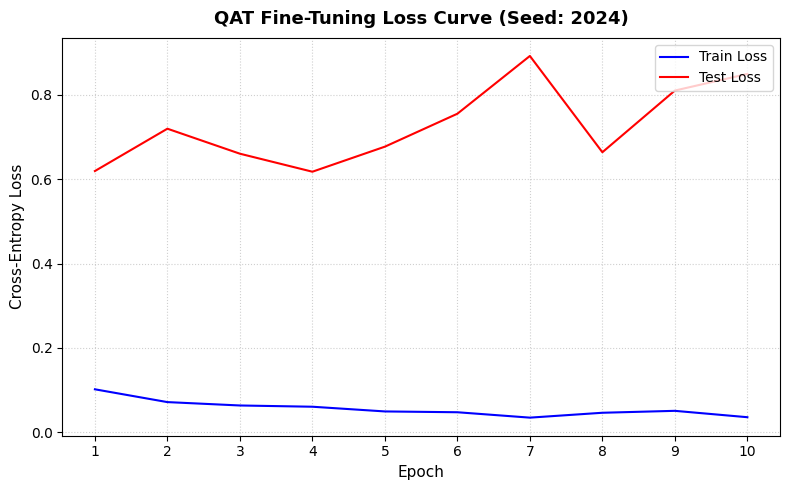

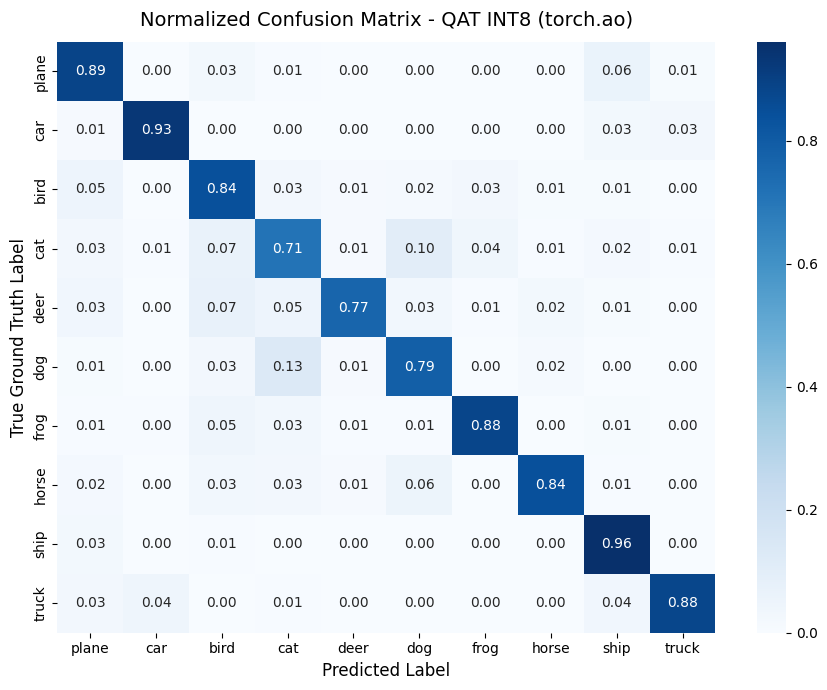


 ANALISIS DEGRADASI AKURASI PER-KELAS: QAT (torch.ao) vs Baseline FP32
Class        | FP32 Acc (%)   | Quant Acc (%)  | Degradasi / Delta (%)
----------------------------------------------------------------------
deer         | 88.00          | 76.50          | -11.50%           
horse        | 90.60          | 84.30          | -6.30%            
cat          | 74.70          | 71.10          | -3.60%            
truck        | 91.30          | 88.20          | -3.10%            
frog         | 89.50          | 88.30          | -1.20%            
car          | 92.70          | 93.10          | +0.40%            
dog          | 77.90          | 78.70          | +0.80%            
plane        | 85.10          | 88.80          | +3.70%            
ship         | 88.60          | 96.10          | +7.50%            
bird         | 72.00          | 84.10          | +12.10%           
----------------------------------------------------------------------
---> KELAS PALING TERDAMPAK: 'deer'

In [26]:
for run_idx, current_seed in enumerate(SEEDS):
  print(f"\n{'='*30} MEMULAI RUN KE-{run_idx+1} (SEED {current_seed}) {'='*30}")

  # 1. Kunci seed
  set_deterministic_seed(current_seed)

  # 2. Inisialisasi Ulang Data Loader (agar shuffle terpengaruh seed)
  g = torch.Generator()
  g.manual_seed(current_seed)
  train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, generator=g)
  test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

  # 3. Pemuatan Checkpoint Model PyTorch Sesuai Seed
  model_checkpoint_path = os.path.join(MODEL_CHECKPOINT_DIR, f"model_vgg16_fp32_baseline_seed{current_seed}.pth")
  model = VGG16(input_channel, num_classes).to(device)
  checkpoint = torch.load(model_checkpoint_path, map_location="cpu")
  model.load_state_dict(checkpoint['model_state_dict'] if 'model_state_dict' in checkpoint else checkpoint)
  print(f"Checkpoint {model_checkpoint_path} berhasil dimuat.")

  # 4. Confusion Matrix Baseline FP32
  model_cpu = copy.deepcopy(model).to("cpu")
  y_true, y_pred_fp32 = get_all_predictions_torch(model_cpu, test_loader, eval_device="cpu")
  plot_and_save_confusion_matrix(
      y_true,
      y_pred_fp32,
      title="Normalized Confusion Matrix - Baseline VGG16 FP32 (PyTorch)",
      save_path=os.path.join(FIGURE_DIR, "cm_vgg16_fp32_baseline_seed"+str(current_seed)+".png")
  )

  # 5. Eksekusi PTSQ (torch.ao)
  model_ptsq = VGG16_Quantization(input_channel, num_classes).to("cpu")
  model_ptsq.load_state_dict(model_cpu.state_dict())
  model_ptsq.eval()
  model_ptsq.qconfig = torch.ao.quantization.get_default_qconfig('fbgemm')
  model_ptsq_fused = torch.ao.quantization.fuse_modules(model_ptsq, [['layer1.0','layer1.1','layer1.2'],
                                                                      ['layer2.0','layer2.1','layer2.2'],
                                                                      ['layer3.0','layer3.1','layer3.2'],
                                                                      ['layer4.0','layer4.1','layer4.2'],
                                                                      ['layer5.0','layer5.1','layer5.2'],
                                                                      ['layer6.0','layer6.1','layer6.2'],
                                                                      ['layer7.0','layer7.1','layer7.2'],
                                                                      ['layer8.0','layer8.1','layer8.2'],
                                                                      ['layer9.0','layer9.1','layer9.2'],
                                                                      ['layer10.0','layer10.1','layer10.2'],
                                                                      ['layer11.0','layer11.1','layer11.2'],
                                                                      ['layer12.0','layer12.1','layer12.2'],
                                                                      ['layer13.0','layer13.1','layer13.2'],
                                                                      ['fc.1','fc.2'],
                                                                      ['fc1.1','fc1.2']])
  model_ptsq_prepared = torch.ao.quantization.prepare(model_ptsq_fused)

  # Kalibrasi
  with torch.inference_mode():
    for calib_batch in test_loader:
      model_ptsq_prepared(calib_batch[0].to("cpu"))
      break
  model_int8_ptsq = torch.ao.quantization.convert(model_ptsq_prepared)

  # Evaluasi PTSQ
  _, y_pred_ptsq = get_all_predictions_torch(model_int8_ptsq, test_loader, eval_device="cpu")
  plot_and_save_confusion_matrix(
      y_true,
      y_pred_ptsq,
      title="Normalized Confusion Matrix - PTSQ INT8 (torch.ao)",
      save_path=os.path.join(FIGURE_DIR, "cm_vgg16_ptsq_torch_ao_seed"+str(current_seed)+".png")
  )
  analyze_most_degraded_classes(y_true, y_pred_fp32, y_pred_ptsq, method_name="PTSQ (torch.ao)")
  path_model_ptsq = os.path.join(MODEL_CHECKPOINT_DIR, "model_vgg16_ptsq_torch_ao_seed"+str(current_seed)+".pth")
  torch.save(model_int8_ptsq.state_dict(), path_model_ptsq)

  # 6. Eksekusi PTDQ (torch.ao)
  model_int8_ptdq = torch.ao.quantization.quantize_dynamic(
      model_cpu, {torch.nn.Linear}, dtype=torch.qint8
  )
  _, y_pred_ptdq = get_all_predictions_torch(model_int8_ptdq, test_loader, eval_device="cpu")
  plot_and_save_confusion_matrix(
      y_true,
      y_pred_ptdq,
      title="Normalized Confusion Matrix - PTDQ INT8 (torch.ao)",
      save_path=os.path.join(FIGURE_DIR, "cm_vgg16_ptdq_torch_ao_seed"+str(current_seed)+".png")
  )
  analyze_most_degraded_classes(y_true, y_pred_fp32, y_pred_ptdq, method_name="PTDQ (torch.ao)")
  path_model_ptdq = os.path.join(MODEL_CHECKPOINT_DIR, "model_vgg16_ptdq_torch_ao_seed"+str(current_seed)+".pth")
  torch.save(model_int8_ptdq.state_dict(), path_model_ptdq)

  # 7. Eksekusi QAT (torch.ao)
  qat_base = copy.deepcopy(model_cpu)
  qat_fused = torch.quantization.fuse_modules(qat_base, [['layer1.0','layer1.1','layer1.2'],
                                                          ['layer2.0','layer2.1','layer2.2'],
                                                          ['layer3.0','layer3.1','layer3.2'],
                                                          ['layer4.0','layer4.1','layer4.2'],
                                                          ['layer5.0','layer5.1','layer5.2'],
                                                          ['layer6.0','layer6.1','layer6.2'],
                                                          ['layer7.0','layer7.1','layer7.2'],
                                                          ['layer8.0','layer8.1','layer8.2'],
                                                          ['layer9.0','layer9.1','layer9.2'],
                                                          ['layer10.0','layer10.1','layer10.2'],
                                                          ['layer11.0','layer11.1','layer11.2'],
                                                          ['layer12.0','layer12.1','layer12.2'],
                                                          ['layer13.0','layer13.1','layer13.2'],
                                                          ['fc.1','fc.2'],
                                                          ['fc1.1','fc1.2']], inplace=True)
  quantized_qat = VGG16_Quantization2(fp32_model=qat_fused)
  quantized_qat.qconfig = torch.quantization.get_default_qconfig("fbgemm")
  torch.quantization.prepare_qat(quantized_qat, inplace=True)
  quantized_qat.to(device)

  # Fine-tuning dengan learning rate rendah
  optimizer_qat = torch.optim.Adam(params=quantized_qat.parameters(), lr=0.0001)
  loss_fn = nn.CrossEntropyLoss()
  qat_train_loss_history = []
  qat_test_loss_history = []
  print(f"\n--- Memulai Fine-Tuning QAT (Seed: {current_seed}) ---")
  for epoch in range(num_epochs_qat):
    quantized_qat.train()
    train_batch_losses = []
    for images, labels in train_loader:
      images = images.to(device)
      labels_onehot = func.one_hot(labels, num_classes).to(device).float()
      optimizer_qat.zero_grad()
      y_pred = quantized_qat(images)
      loss = loss_fn(y_pred, labels_onehot)
      loss.backward()
      optimizer_qat.step()
      train_batch_losses.append(loss.item())

    epoch_train_loss = np.mean(train_batch_losses)
    qat_train_loss_history.append(epoch_train_loss)

    quantized_qat.eval()
    test_batch_losses = []
    with torch.inference_mode():
      for images, labels in test_loader:
        images = images.to(device)
        labels_onehot = func.one_hot(labels, num_classes).to(device).float()

        y_pred = quantized_qat(images)
        loss = loss_fn(y_pred, labels_onehot)
        test_batch_losses.append(loss.item())

    epoch_test_loss = np.mean(test_batch_losses)
    qat_test_loss_history.append(epoch_test_loss)
    print(f"Epoch [{epoch+1}/{num_epochs_qat}] -> QAT Train Loss: {epoch_train_loss:.4f} | QAT Test Loss: {epoch_test_loss:.4f}")

  all_qat_train_losses.append(epoch_train_loss)
  all_qat_test_losses.append(epoch_test_loss)
  plt.figure(figsize=(8, 5))
  epochs_range = range(1, num_epochs_qat + 1)
  plt.plot(epochs_range, qat_train_loss_history, '-', color='blue', label='Train Loss')
  plt.plot(epochs_range, qat_test_loss_history, '-', color='red', label='Test Loss')

  plt.title(f'QAT Fine-Tuning Loss Curve (Seed: {current_seed})', fontsize=13, fontweight='bold', pad=10)
  plt.xlabel('Epoch', fontsize=11)
  plt.ylabel('Cross-Entropy Loss', fontsize=11)
  plt.xticks(epochs_range)
  plt.grid(True, linestyle=':', alpha=0.6)
  plt.legend(loc='upper right', frameon=True)
  plt.tight_layout()
  qat_plot_filename = f"qat_loss_curve_seed_{current_seed}.png"
  qat_plot_path = os.path.join(QAT_PLOT_DIR, qat_plot_filename)
  plt.savefig(qat_plot_path, dpi=300, bbox_inches='tight')

  quantized_qat.to("cpu")
  model_int8_qat = torch.quantization.convert(quantized_qat, inplace=False)

  # Evaluasi QAT
  _, y_pred_qat = get_all_predictions_torch(model_int8_qat, test_loader, eval_device="cpu")
  plot_and_save_confusion_matrix(
      y_true,
      y_pred_qat,
      title="Normalized Confusion Matrix - QAT INT8 (torch.ao)",
      save_path=os.path.join(FIGURE_DIR, "cm_vgg16_qat_torch_ao_seed"+str(current_seed)+".png")
  )
  analyze_most_degraded_classes(y_true, y_pred_fp32, y_pred_qat, method_name="QAT (torch.ao)")
  path_model_qat = os.path.join(MODEL_CHECKPOINT_DIR, "model_vgg16_qat_torch_ao_seed"+str(current_seed)+".pth")
  torch.save(model_int8_qat.state_dict(), path_model_qat)

In [31]:
temp_qat_train_losses_42 = np.array((0.0971, 0.0960, 0.0508, 0.0456, 0.0482, 0.0457, 0.0386, 0.0433, 0.0373, 0.0352))
temp_qat_train_losses_123 = np.array((0.0919, 0.0695, 0.0629, 0.0474, 0.0525, 0.0474, 0.0389, 0.0344, 0.0402, 0.0373))
temp_qat_train_losses_456 = np.array((0.0906, 0.0596, 0.0619, 0.0489, 0.0448, 0.0468, 0.0403, 0.0364, 0.0241, 0.0351))
temp_qat_train_losses_1337 = np.array((0.0993, 0.0681, 0.0660, 0.0631, 0.0563, 0.0498, 0.0460, 0.0450, 0.0288, 0.0438))
temp_qat_train_losses_2024 = np.array((0.1017, 0.0713, 0.0633, 0.0603, 0.0492, 0.0472, 0.0344, 0.0460, 0.0506, 0.0355))
all_qat_train_losses = [temp_qat_train_losses_42, temp_qat_train_losses_123, temp_qat_train_losses_456, temp_qat_train_losses_1337, temp_qat_train_losses_2024]

temp_qat_test_losses_42 = np.array((0.7537, 0.6660, 0.7284, 0.7457, 0.7284, 0.7436, 0.7170, 0.7280, 0.7805, 0.7540))
temp_qat_test_losses_123 = np.array((0.7269, 0.6764, 0.6630, 0.7370, 0.7499, 0.7610, 0.6969, 0.8687, 1.0275, 0.7681))
temp_qat_test_losses_456 = np.array((0.6287, 0.7245, 0.7534, 0.7100, 0.8226, 0.5890, 0.7175, 0.7185, 0.8757, 0.7745))
temp_qat_test_losses_1337 = np.array((0.6483, 0.8499, 0.7508, 0.5835, 0.7112, 0.6823, 0.7070, 0.7064, 0.8095, 0.8247))
temp_qat_test_losses_2024 = np.array((0.6195, 0.7199, 0.6606, 0.6178, 0.6773, 0.7554, 0.8924, 0.6641, 0.8104, 0.8498))
all_qat_test_losses = [temp_qat_test_losses_42, temp_qat_test_losses_123, temp_qat_test_losses_456, temp_qat_test_losses_1337, temp_qat_test_losses_2024]

[AGGREGATE PLOT SAVED] Grafik agregat QAT disimpan ke: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/qat_loss_curves/qat_aggregated_loss_curve.png


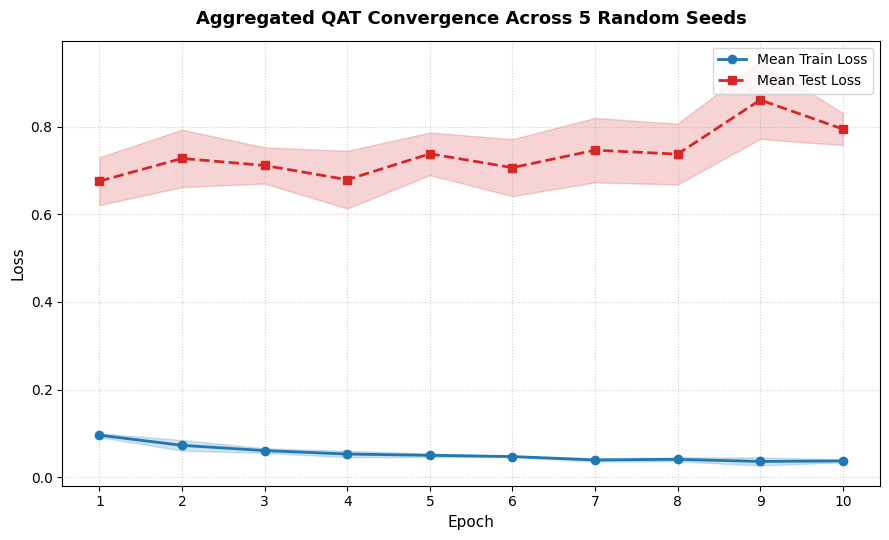

In [37]:
# Plot Agregat Mean ± Std Dev Loss QAT Lintas Semua 5 Seeds
epochs = np.arange(1, num_epochs_qat + 1)
mean_train = np.mean(all_qat_train_losses, axis=0)
std_train = np.std(all_qat_train_losses, axis=0)
mean_test = np.mean(all_qat_test_losses, axis=0)
std_test = np.std(all_qat_test_losses, axis=0)

plt.figure(figsize=(9, 5.5))
# Plot Mean & Confidence Interval (±1 Std Dev)
plt.plot(epochs, mean_train, 'o-', color='#1f77b4', label='Mean Train Loss', linewidth=2)
plt.fill_between(epochs, mean_train - std_train, mean_train + std_train, color='#1f77b4', alpha=0.2)

plt.plot(epochs, mean_test, 's--', color='#d62728', label='Mean Test Loss', linewidth=2)
plt.fill_between(epochs, mean_test - std_test, mean_test + std_test, color='#d62728', alpha=0.2)

plt.title('Aggregated QAT Convergence Across 5 Random Seeds', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.xticks(epochs)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()

agg_plot_path = os.path.join(QAT_PLOT_DIR, "qat_aggregated_loss_curve.png")
plt.savefig(agg_plot_path, dpi=300, bbox_inches='tight')
print(f"[AGGREGATE PLOT SAVED] Grafik agregat QAT disimpan ke: {agg_plot_path}")
plt.show()

In [ ]:
if os.path.exists(CSV_LOG_PATH):
  df_all_experiments = pd.read_csv(CSV_LOG_PATH)
  print("\n=== REKAPITULASI SELURUH EKSPERIMEN DARI FILE EKSTERNAL ===")
  display(df_all_experiments)
else:
  print("Belum ada file log yang tersimpan.")


=== REKAPITULASI SELURUH EKSPERIMEN DARI FILE EKSTERNAL ===


,timestamp,seed,framework,method,runtime_backend,quant_scheme,accuracy,macro_precision,macro_recall,macro_f1,model_size_mb,size_reduction_pct,latency_mean_ms,latency_std_ms
0,2026-09-22 04:42:25,42,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8229,0.8398,0.8229,0.8252,128.42,0.00,22.62,1.99
1,2026-09-22 04:43:25,42,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8245,0.8400,0.8245,0.8271,32.34,74.82,7.88,1.04
2,2026-09-22 04:44:52,42,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),0.8230,0.8393,0.8230,0.8253,74.30,42.14,18.44,2.07
3,2026-09-22 04:51:57,42,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),0.8528,0.8577,0.8528,0.8539,32.34,74.82,9.56,0.64
4,2026-09-22 05:01:34,123,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8358,0.8474,0.8358,0.8356,128.42,0.00,20.76,1.66
5,2026-09-22 05:02:27,123,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8276,0.8435,0.8276,0.8279,32.34,74.82,10.29,1.91
6,2026-09-22 05:03:49,123,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),0.8351,0.8467,0.8351,0.8348,74.30,42.14,17.50,1.64
7,2026-09-22 05:10:52,123,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),0.7745,0.8534,0.7745,0.7855,32.34,74.82,7.17,0.86
8,2026-09-22 05:20:30,456,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8161,0.8381,0.8161,0.8209,128.42,0.00,21.72,1.80
9,2026-09-22 05:21:24,456,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8109,0.8359,0.8109,0.8161,32.34,74.82,6.68,0.66


## **4. Analisis Trade-off & Efficiency Score**

In [ ]:
import pandas as pd
import os
import numpy as np
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Analisis Trade-off Multi-Seed (5 Runs)
LOG_DIR = "/content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs"
RAW_LOG_PATH = os.path.join(LOG_DIR, "cifar10_quantization_benchmark.csv")
SUMMARY_SAVE_PATH = os.path.join(LOG_DIR, "cifar10_quantization_summary.csv")

# 1. Validasi Keberadaan File Log Mentah
if not os.path.exists(RAW_LOG_PATH):
  raise FileNotFoundError(f"File log mentah belum ditemukan pada: {RAW_LOG_PATH}")

df_raw = pd.read_csv(RAW_LOG_PATH)
print(f"Total baris log eksperimen terbaca: {len(df_raw)}")

# Filter data agar memastikan hanya 5 seed target yang dianalisis
TARGET_SEEDS = [42, 123, 456, 1337, 2024]
df_raw = df_raw[df_raw['seed'].isin(TARGET_SEEDS)].copy()
display(df_raw)

Total baris log eksperimen terbaca: 35


,timestamp,seed,framework,method,runtime_backend,quant_scheme,accuracy,macro_precision,macro_recall,macro_f1,model_size_mb,size_reduction_pct,latency_mean_ms,latency_std_ms
0,2026-09-22 04:42:25,42,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8229,0.8398,0.8229,0.8252,1.284200e+02,0.00,22.62,1.99
1,2026-09-22 04:43:25,42,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8245,0.8400,0.8245,0.8271,3.234000e+01,74.82,7.88,1.04
2,2026-09-22 04:44:52,42,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),0.8230,0.8393,0.8230,0.8253,7.430000e+01,42.14,18.44,2.07
3,2026-09-22 04:51:57,42,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),0.8528,0.8577,0.8528,0.8539,3.234000e+01,74.82,9.56,0.64
4,2026-09-22 05:01:34,123,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8358,0.8474,0.8358,0.8356,1.284200e+02,0.00,20.76,1.66
5,2026-09-22 05:02:27,123,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8276,0.8435,0.8276,0.8279,3.234000e+01,74.82,10.29,1.91
6,2026-09-22 05:03:49,123,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),0.8351,0.8467,0.8351,0.8348,7.430000e+01,42.14,17.50,1.64
7,2026-09-22 05:10:52,123,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),0.7745,0.8534,0.7745,0.7855,3.234000e+01,74.82,7.17,0.86
8,2026-09-22 05:20:30,456,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),0.8161,0.8381,0.8161,0.8209,1.284200e+02,0.00,21.72,1.80
9,2026-09-22 05:21:24,456,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),0.8109,0.8359,0.8109,0.8161,3.234000e+01,74.82,6.68,0.66


In [ ]:
# 2. Konversi Metrik Desimal ke Persentase (jika file mentah mencatat skala 0-1)
for col in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']:
  if df_raw[col].max() <= 1.0:
    df_raw[col] = df_raw[col] * 100.0

# 3. Agregasi Statistik (Mean & Std) Berdasarkan Metode dan Runtime Engine
grouped = df_raw.groupby(['framework', 'method', 'runtime_backend', 'quant_scheme'], as_index=False)

df_agg = grouped.agg(
    acc_mean=('accuracy', 'mean'),
    acc_std=('accuracy', 'std'),
    prec_mean=('macro_precision', 'mean'),
    prec_std=('macro_precision', 'std'),
    rec_mean=('macro_recall', 'mean'),
    rec_std=('macro_recall', 'std'),
    f1_mean=('macro_f1', 'mean'),
    f1_std=('macro_f1', 'std'),
    size_mean=('model_size_mb', 'mean'),
    size_std=('model_size_mb', 'std'),
    lat_mean=('latency_mean_ms', 'mean'),
    lat_std=('latency_mean_ms', 'std'), # Variasi mean latency lintas 5 seed
    runs_count=('seed', 'count')
)
df_agg

,framework,method,runtime_backend,quant_scheme,acc_mean,acc_std,prec_mean,prec_std,rec_mean,rec_std,f1_mean,f1_std,size_mean,size_std,lat_mean,lat_std,runs_count
0,ONNX,Baseline FP32,ONNX Runtime CPU,None (FP32),83.998,1.508450,84.526,1.261955,83.998,1.508450,83.930,1.575595,1.346050e+08,0.000000,15.894,1.304619,5
1,ONNX,PTDQ,ONNX Runtime CPU,Dynamic (QUInt8),83.964,1.513020,84.490,1.272733,83.964,1.513020,83.896,1.576398,3.372250e+07,2.588436,14.172,2.432636,5
2,ONNX,PTSQ,ONNX Runtime CPU,Asymmetric QDQ (QInt8),83.858,1.663992,84.408,1.417875,83.858,1.663992,83.812,1.715567,3.372936e+07,0.000000,5.106,0.063875,5
3,PyTorch,Baseline FP32,PyTorch CPU,None (FP32),82.882,0.892115,84.218,0.384539,82.882,0.892115,83.082,0.738153,1.284200e+02,0.000000,23.250,3.424456,5
4,torch.ao,PTDQ,PyTorch CPU,Dynamic (Linear Only),82.886,0.874631,84.204,0.355921,82.886,0.874631,83.080,0.719131,7.430000e+01,0.000000,19.262,3.109400,5
5,torch.ao,PTSQ,PyTorch CPU (FBGEMM),Asymmetric (Per-Tensor),82.632,0.977993,84.128,0.401833,82.632,0.977993,82.866,0.847278,3.234000e+01,0.000000,7.734,1.518891,5
6,torch.ao,QAT,PyTorch CPU (FBGEMM),Asymmetric (STE Simulated),83.952,3.671794,86.038,0.664357,83.952,3.671794,84.232,3.220096,3.234000e+01,0.000000,7.542,1.147332,5


In [ ]:
# 4. Ambil Nilai Referensi Baseline FP32 (PyTorch CPU) Secara Dinamis
baseline_row = df_agg[(df_agg['framework'] == 'PyTorch') & (df_agg['method'] == 'Baseline FP32')]

if baseline_row.empty:
  raise ValueError("Data 'Baseline FP32' untuk PyTorch tidak ditemukan dalam file log.")

baseline_acc = baseline_row['acc_mean'].values[0]
baseline_size = baseline_row['size_mean'].values[0]
baseline_lat = baseline_row['lat_mean'].values[0]

print(f"\nReferensi Baseline FP32 (PyTorch CPU):")
print(f"- Accuracy : {baseline_acc:.2f}%")
print(f"- Size     : {baseline_size:.2f} MB")
print(f"- Latency  : {baseline_lat:.2f} ms")


Referensi Baseline FP32 (PyTorch CPU):
- Accuracy : 82.88%
- Size     : 128.42 MB
- Latency  : 23.25 ms


In [ ]:
# 5. Kalkulasi Metrik Trade-off & Efficiency Score
# Rasio reduksi ukuran model (%)
df_agg['Size Reduction (%)'] = (1.0 - (df_agg['size_mean'] / baseline_size)) * 100.0

# Akselerasi relatif terhadap Baseline PyTorch CPU (x-fold)
df_agg['Speedup (x)'] = baseline_lat / df_agg['lat_mean']

# Pareto Efficiency Score (Semakin tinggi semakin optimal trade-off-nya)
# Rumus: (Acc / Base_Acc) * (Base_Size / Size) * (Base_Lat / Lat)
df_agg['Efficiency Score'] = (
    (df_agg['acc_mean'] / baseline_acc) *
    (baseline_size / df_agg['size_mean']) *
    (baseline_lat / df_agg['lat_mean'])
).round(2)

In [ ]:
# 6. Format Kolom untuk Tabel Pelaporan Naskah Ilmiah (Mean ± Std)
df_display = pd.DataFrame()
df_display['Framework'] = df_agg['framework']
df_display['Method'] = df_agg['method']
df_display['Runtime Engine'] = df_agg['runtime_backend']
df_display['Accuracy (%)'] = df_agg.apply(lambda r: f"{r['acc_mean']:.2f} ± {r['acc_std']:.2f}", axis=1)
df_display['Precision (%)'] = df_agg.apply(lambda r: f"{r['prec_mean']:.2f} ± {r['prec_std']:.2f}", axis=1)
df_display['Recall (%)'] = df_agg.apply(lambda r: f"{r['rec_mean']:.2f} ± {r['rec_std']:.2f}", axis=1)
df_display['Macro F1 (%)'] = df_agg.apply(lambda r: f"{r['f1_mean']:.2f} ± {r['f1_std']:.2f}", axis=1)
df_display['Size (MB)'] = df_agg.apply(lambda r: f"{r['size_mean']:.2f}", axis=1) # Ukuran model bersifat statis/deterministik
df_display['Size Reduction (%)'] = df_agg['Size Reduction (%)'].round(2)
df_display['Latency CPU (ms)'] = df_agg.apply(lambda r: f"{r['lat_mean']:.2f} ± {r['lat_std']:.2f}", axis=1)
df_display['Speedup (x)'] = df_agg['Speedup (x)'].round(2)
df_display['Efficiency Score'] = df_agg['Efficiency Score']
df_display['Runs'] = df_agg['runs_count']

# Urutkan berdasarkan Efficiency Score tertinggi
df_display = df_display.sort_values(by='Efficiency Score', ascending=False).reset_index(drop=True)

print("\n=== COMPREHENSIVE PARETO & EFFICIENCY TRADE-OFF TABLE (5 SEEDS AGGREGATED) ===")
display(df_display)


=== COMPREHENSIVE PARETO & EFFICIENCY TRADE-OFF TABLE (5 SEEDS AGGREGATED) ===


,Framework,Method,Runtime Engine,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Size (MB),Size Reduction (%),Latency CPU (ms),Speedup (x),Efficiency Score,Runs
0,torch.ao,QAT,PyTorch CPU (FBGEMM),83.95 ± 3.67,86.04 ± 0.66,83.95 ± 3.67,84.23 ± 3.22,32.34,7.482000e+01,7.54 ± 1.15,3.08,12.40,5
1,torch.ao,PTSQ,PyTorch CPU (FBGEMM),82.63 ± 0.98,84.13 ± 0.40,82.63 ± 0.98,82.87 ± 0.85,32.34,7.482000e+01,7.73 ± 1.52,3.01,11.90,5
2,torch.ao,PTDQ,PyTorch CPU,82.89 ± 0.87,84.20 ± 0.36,82.89 ± 0.87,83.08 ± 0.72,74.30,4.214000e+01,19.26 ± 3.11,1.21,2.09,5
3,PyTorch,Baseline FP32,PyTorch CPU,82.88 ± 0.89,84.22 ± 0.38,82.88 ± 0.89,83.08 ± 0.74,128.42,0.000000e+00,23.25 ± 3.42,1.00,1.00,5
4,ONNX,PTSQ,ONNX Runtime CPU,83.86 ± 1.66,84.41 ± 1.42,83.86 ± 1.66,83.81 ± 1.72,33729361.00,-2.626478e+07,5.11 ± 0.06,4.55,0.00,5
5,ONNX,Baseline FP32,ONNX Runtime CPU,84.00 ± 1.51,84.53 ± 1.26,84.00 ± 1.51,83.93 ± 1.58,134604984.00,-1.048161e+08,15.89 ± 1.30,1.46,0.00,5
6,ONNX,PTDQ,ONNX Runtime CPU,83.96 ± 1.51,84.49 ± 1.27,83.96 ± 1.51,83.90 ± 1.58,33722500.80,-2.625944e+07,14.17 ± 2.43,1.64,0.00,5


In [ ]:
# 7. Simpan Tabel Ringkasan Akhir
df_display.to_csv(SUMMARY_SAVE_PATH, index=False)
print(f"\nTabel ringkasan trade-off berhasil disimpan ke: {SUMMARY_SAVE_PATH}")


Tabel ringkasan trade-off berhasil disimpan ke: /content/drive/MyDrive/Dokumentasi S3 ITB/Eksplorasi Efisiensi Model (Quantization dan Reduce Significant Bit)/experiment_logs/cifar10_quantization_summary.csv
